# PRCP-1001: Rice leaf disease detection

The job here is to look at a photo of a rice leaf and say which of three diseases it has: **bacterial leaf blight**, **brown spot** or **leaf smut**. The dataset is only 119 photos, so this is a small problem, and most of the effort in this notebook went into evaluating the models honestly rather than chasing a few extra points of accuracy.

Everything is done in TensorFlow/Keras. scikit-learn is only used for splitting the data and computing metrics.

## What the brief asks for and where it is

| Deliverable in the brief | Where to find it |
|---|---|
| Task 1: complete data analysis report | Section 1 |
| Task 2: model that classifies the three diseases | Sections 4 and 6 (final model in 6 and 7) |
| Task 3: analyse data augmentation and other techniques | Section 3 |
| Model comparison report and the best model for production | Section 5 |
| Report on the challenges faced | Section 8 |

One naming thing: the brief says "leaf blast" in Task 2 but the dataset folder (and the class list in the brief) says leaf smut. I used the folder names.

## Short version of the results

* Final model: MobileNetV2 with ImageNet weights, backbone frozen, a small classification head on top, flip augmentation, 224x224 input.
* 5-fold cross-validation (grouped so photos of the same leaf stay together): **92.4% accuracy +/- 4.7**, macro F1 0.922.
* On the single 20-image test split it got 85%. That split is tiny (one image is 5 points), so I trust the cross-validated number more.
* In cross-validation 9 of the 119 images were misclassified, 6 of them leaf smut.
* Things that did not help: rotation/zoom/colour augmentation, fine-tuning the backbone, a wider input, a bigger backbone.

## How to run it

Put the three class folders next to this notebook (the code downloads the zip if they are missing) and run all cells. A full run on CPU takes a long time, mostly the cross-validation, so there is a `FAST_MODE` switch in the first cell for a quick check. All results below are from the full run. Python packages are listed in `requirements.txt`.

## 0. Setup

All the settings are in the first cell. `FAST_MODE` cuts the number of folds and epochs and skips the two slowest things (ResNet50 cross-validation and the input size study); I only use it to check that the notebook runs end to end. `SIM_THRESH` is the similarity threshold used to find near-duplicate photos in section 1.8. The random seed is 42 everywhere. There is no GPU on this machine, which is why training takes a while.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import zipfile, hashlib, random, time, gc, json, urllib.request, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

FAST_MODE = False
K_FOLDS = 3 if FAST_MODE else 5
CV_EPOCHS = 15 if FAST_MODE else 25
CNN_EPOCHS = 25 if FAST_MODE else 40
RUN_RESIZE_STUDY = not FAST_MODE
RUN_RESNET_CV = not FAST_MODE
SIM_THRESH = 0.70

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BATCH = 16
AUTOTUNE = tf.data.AUTOTUNE
INPUT_MODE = "squash_224"
INPUT_SHAPE = (224, 224, 3)
sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)

def save_fig(name):
    plt.savefig(f"images/{name}.png", dpi=130, bbox_inches="tight")

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
Keras: 3.15.0
GPUs: []


## 1. Data analysis (Task 1)

### 1.1 Loading the data

The images are in one folder per class. The code first looks for those folders next to the notebook and only downloads the zip if they are not there. I end up with 119 images: 40 bacterial leaf blight, 40 brown spot and 39 leaf smut. The brief says 40 per class, so one leaf smut image is missing from the copy I got. I left it as it is.

The file names are camera numbers (DSC_0365, DSC_0366, ...), so photos taken one after another are neighbours in the list. That turns out to matter in section 1.8.

In [2]:
URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
ZIP_PATH = "PRCP-1001-RiceLeaf.zip"
DATA_DIR = "rice_leaf_data"
IMG_EXT = (".jpg", ".jpeg", ".png")

def class_dirs(path):
    out = []
    for d in sorted(os.listdir(path)):
        sub = os.path.join(path, d)
        if os.path.isdir(sub) and not d.startswith((".", "__")):
            n_imgs = sum(f.lower().endswith(IMG_EXT) for f in os.listdir(sub))
            if n_imgs >= 10:
                out.append(d)
    return out

def find_root(base):
    for r, dirs, files in os.walk(base):
        if "__MACOSX" in r:
            continue
        found = class_dirs(r)
        if len(found) >= 2:
            return r, found
    return None, []

ROOT, classes = ".", class_dirs(".")

if len(classes) < 2:
    if not os.path.exists(ZIP_PATH):
        urllib.request.urlretrieve(URL, ZIP_PATH)
    os.makedirs(DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    ROOT, classes = find_root(DATA_DIR)

assert ROOT is not None and len(classes) >= 2, "Class folders not found"

class_to_id = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

rows = []
for c in classes:
    folder = os.path.join(ROOT, c)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(IMG_EXT):
            rows.append({"path": os.path.join(folder, f), "label": c, "label_id": class_to_id[c]})
df = pd.DataFrame(rows)

print("Root:", ROOT)
print("Classes:", classes)
print("Total images:", len(df))
display(df.head())

Root: .
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut', 'images']
Total images: 132


,path,label,label_id
0,./Bacterial leaf blight/DSC_0365.JPG,Bacterial leaf blight,0
1,./Bacterial leaf blight/DSC_0366.jpg,Bacterial leaf blight,0
2,./Bacterial leaf blight/DSC_0367.JPG,Bacterial leaf blight,0
3,./Bacterial leaf blight/DSC_0370.jpg,Bacterial leaf blight,0
4,./Bacterial leaf blight/DSC_0372.JPG,Bacterial leaf blight,0


label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
images                   13
Name: count, dtype: int64


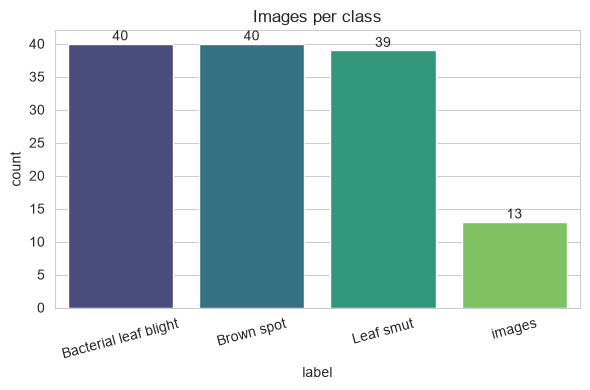

In [3]:
counts = df["label"].value_counts().reindex(classes)
print(counts)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=counts.index, y=counts.values, palette="viridis")
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.5, str(v), ha="center")
plt.title("Images per class")
plt.ylabel("count")
plt.xticks(rotation=15)
plt.tight_layout()
save_fig("class_balance")
plt.show()

### 1.2 Class balance

The classes are almost perfectly balanced (40 / 40 / 39), so I did not use class weights or resampling. Accuracy is fine for comparing models here, but I also report macro F1 so a weak class cannot hide behind the others.

### 1.3 Image sizes and file integrity

Next I check for corrupt files and look at how big the photos are.

Corrupted images: 0


,width,height,size_kb
count,132.00,132.00,132.00
mean,2305.56,704.67,334.46
std,1115.82,302.35,288.74
min,250.00,71.00,22.76
25%,948.00,505.00,76.94
50%,3081.00,897.00,376.06
75%,3081.00,897.00,431.28
max,3081.00,1160.00,2032.88


mode
RGB     119
RGBA     13
Name: count, dtype: int64
Unique sizes: 47


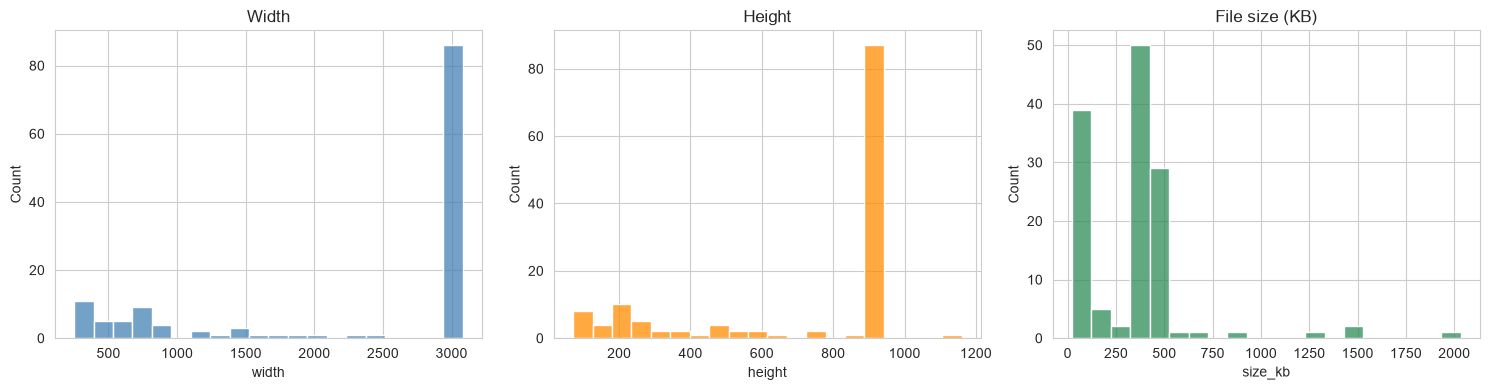

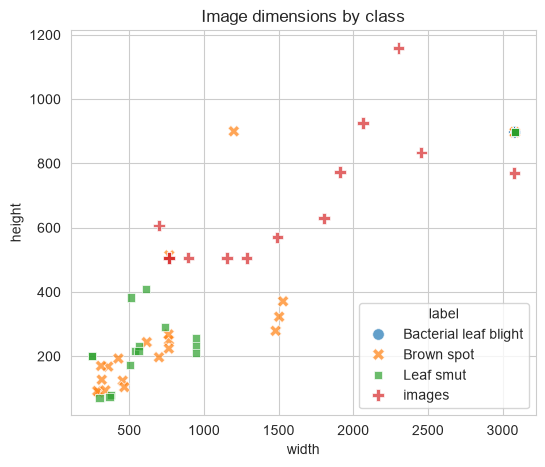

In [4]:
def get_props(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size
            mode = im.mode
        return {"width": w, "height": h, "mode": mode, "size_kb": os.path.getsize(p) / 1024, "corrupt": False}
    except Exception:
        return {"width": np.nan, "height": np.nan, "mode": None, "size_kb": np.nan, "corrupt": True}

props = pd.DataFrame([get_props(p) for p in df["path"]])
df = pd.concat([df, props], axis=1)

print("Corrupted images:", int(df["corrupt"].sum()))
df = df[~df["corrupt"]].reset_index(drop=True)

display(df[["width", "height", "size_kb"]].describe().round(2))
print(df["mode"].value_counts())
print("Unique sizes:", df.groupby(["width", "height"]).size().shape[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["width"], bins=20, ax=axes[0], color="steelblue")
axes[0].set_title("Width")
sns.histplot(df["height"], bins=20, ax=axes[1], color="darkorange")
axes[1].set_title("Height")
sns.histplot(df["size_kb"], bins=20, ax=axes[2], color="seagreen")
axes[2].set_title("File size (KB)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="width", y="height", hue="label", style="label", s=70, alpha=0.7)
plt.title("Image dimensions by class")
save_fig("image_dimensions")
plt.show()

No corrupt files, and every image is RGB. The sizes are all over the place: widths from 250 to 3081 px, heights from 71 to 900 px, 34 different sizes in total. More than half the images are exactly 3081 x 897, which is very wide and thin (about 3.4 : 1). The rest are smaller, some of them tiny.

The scatter plot shows something I did not expect: the small images only exist for brown spot and leaf smut. Every bacterial leaf blight photo is 3081 x 897. This matters for two reasons. Every image has to be resized to go into a CNN, and squeezing a 3.4 : 1 photo into a square will distort it (I compare resizing options in section 2.2). And image size could give away the label, which I test in section 1.7.

For the rest of the analysis the images are loaded into memory as 224 x 224 arrays (119 images, uint8).

In [5]:
def to_array(im, mode):
    im = im.convert("RGB")
    if mode == "squash_224":
        return np.array(im.resize((224, 224), Image.BILINEAR))
    if mode == "wide_224x448":
        return np.array(im.resize((448, 224), Image.BILINEAR))
    if mode == "letterbox_224":
        im = im.copy()
        im.thumbnail((224, 224), Image.BILINEAR)
        arr = np.array(im)
        fill = arr[:5, :5].reshape(-1, 3).mean(axis=0).astype("uint8")
        canvas = np.ones((224, 224, 3), dtype="uint8") * fill
        y0 = (224 - arr.shape[0]) // 2
        x0 = (224 - arr.shape[1]) // 2
        canvas[y0:y0 + arr.shape[0], x0:x0 + arr.shape[1]] = arr
        return canvas
    raise ValueError(mode)

def load_images(mode):
    return np.stack([to_array(Image.open(p), mode) for p in df["path"]]).astype("uint8")

X_all = load_images(INPUT_MODE)
y_all = df["label_id"].values
print("X_all:", X_all.shape, X_all.dtype)
print("y_all:", y_all.shape, np.bincount(y_all))

X_all: (132, 224, 224, 3) uint8
y_all: (132,) [40 40 39 13]


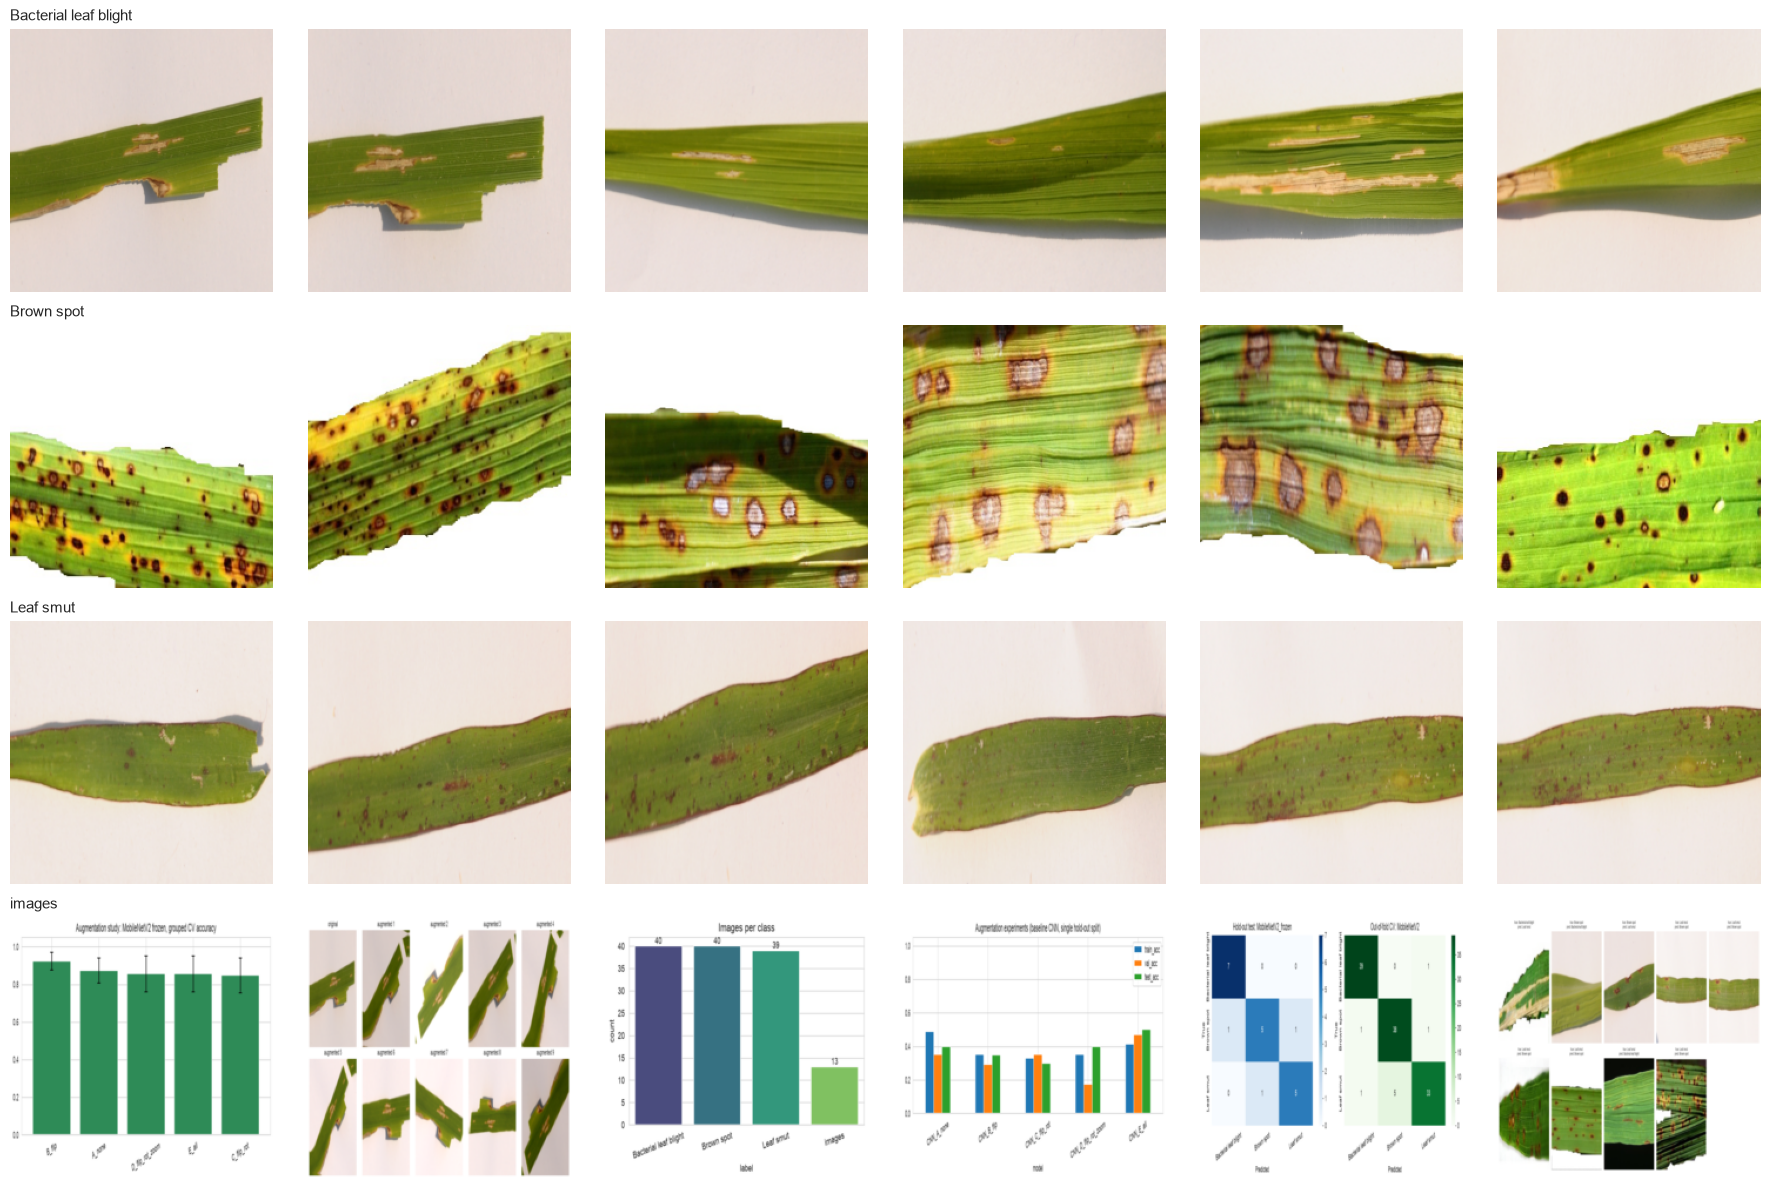

In [6]:
N_SHOW = 6
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(3 * N_SHOW, 3 * NUM_CLASSES))
for ci, c in enumerate(classes):
    idxs = np.where(y_all == ci)[0][:N_SHOW]
    for j, i in enumerate(idxs):
        axes[ci, j].imshow(X_all[i])
        axes[ci, j].axis("off")
        if j == 0:
            axes[ci, j].set_title(c, fontsize=11, loc="left")
plt.tight_layout()
save_fig("sample_grid")
plt.show()

### 1.4 What the leaves look like

Bacterial leaf blight shows long pale or yellowish streaks along the leaf. Brown spot has dark round spots, often with a lighter centre and a yellow halo, and many of those photos have a plain white background. Leaf smut has many small dark specks spread over a green leaf, shot against a pinkish background.

Two things caught my eye here. The backgrounds are not the same across classes, so I want to check later that the model is not using them. And some neighbouring images look like the same leaf photographed twice (the first two bacterial leaf blight images, for example). That is the near-duplicate problem in section 1.8.

Mean RGB per class


,R,G,B
Bacterial leaf blight,194.20,188.89,152.22
Brown spot,191.29,189.45,126.64
Leaf smut,180.11,181.93,141.39
images,204.16,212.72,201.24


Std RGB per class


,R,G,B
Bacterial leaf blight,58.17,50.53,89.25
Brown spot,53.47,49.90,94.83
Leaf smut,69.58,60.61,92.42
images,74.15,55.74,75.88


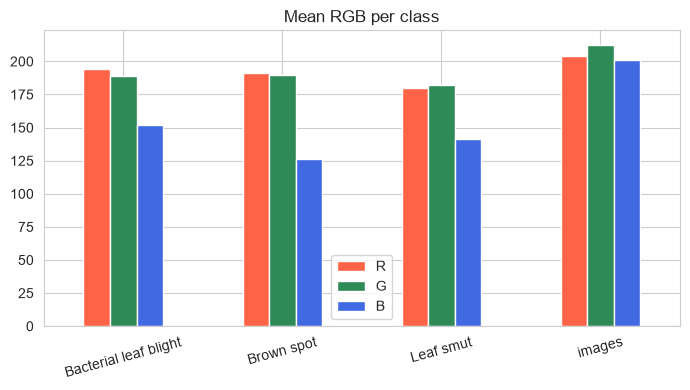

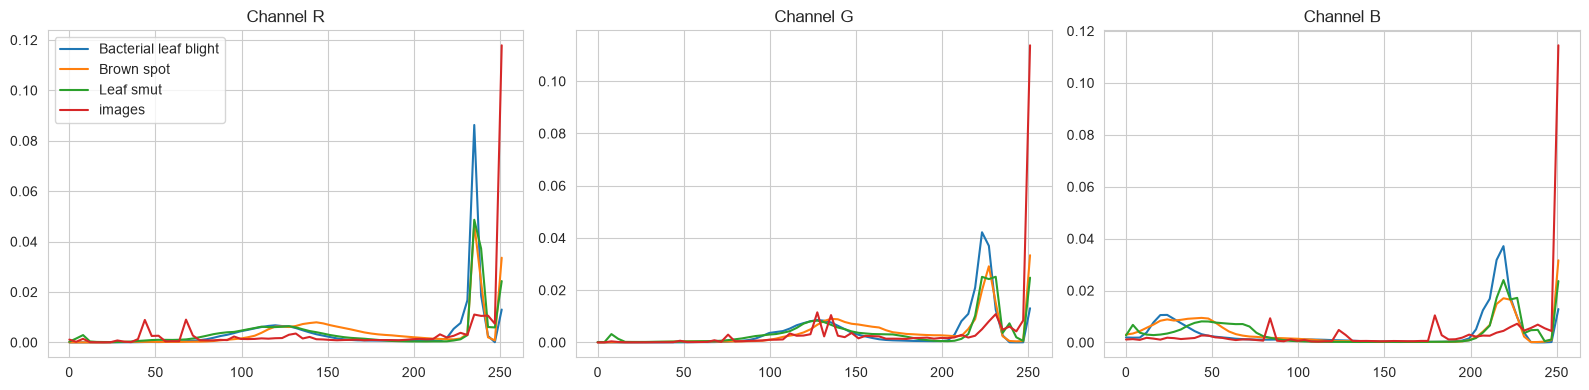

In [7]:
mean_rgb = pd.DataFrame(
    [X_all[y_all == ci].reshape(-1, 3).mean(axis=0) for ci in range(NUM_CLASSES)],
    index=classes, columns=["R", "G", "B"]
)
std_rgb = pd.DataFrame(
    [X_all[y_all == ci].reshape(-1, 3).std(axis=0) for ci in range(NUM_CLASSES)],
    index=classes, columns=["R", "G", "B"]
)
print("Mean RGB per class")
display(mean_rgb.round(2))
print("Std RGB per class")
display(std_rgb.round(2))

mean_rgb.plot(kind="bar", figsize=(7, 4), color=["tomato", "seagreen", "royalblue"])
plt.title("Mean RGB per class")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

palette = sns.color_palette("tab10", NUM_CLASSES)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for chi, ch in enumerate(["R", "G", "B"]):
    for ci, c in enumerate(classes):
        hist, edges = np.histogram(X_all[y_all == ci][..., chi].ravel(), bins=64, range=(0, 255), density=True)
        axes[chi].plot(edges[:-1], hist, label=c, color=palette[ci])
    axes[chi].set_title("Channel " + ch)
axes[0].legend()
plt.tight_layout()
plt.show()

### 1.5 Colour

Red and green are close for all three classes. Blue is lowest for brown spot (127 against 152 and 141), probably because of the yellow-green leaves. In the histograms every class has a big spike near 220 to 250, which is the background, and brown spot also has a spike at 255 from the pure white backgrounds. Away from the background peak the three classes overlap quite a bit, so colour alone will not separate them. The model has to use lesion shape and pattern.

Exact duplicate files: 0


sharpness                                           \
                          count    mean     std     min     25%      50%   
label                                                                      
Bacterial leaf blight      40.0   99.74   67.20   18.84   56.31    79.11   
Brown spot                 40.0  134.89  147.75   17.48   32.62    59.23   
Leaf smut                  39.0  159.01  203.25   21.55   54.20    79.19   
images                     13.0  975.64  269.28  553.38  861.96  1000.19   

                                        brightness                         \
                           75%      max      count    mean    std     min   
label                                                                       
Bacterial leaf blight   113.12   322.53       40.0  178.43  15.18  151.57   
Brown spot              211.95   595.28       40.0  169.13  25.37  106.38   
Leaf smut               152.95  1128.67       39.0  167.81  38.49   75.94   
images                 1082.51  1642.01       13.0  206.04  22.22  179.97   

                                                       
                          25%     50%     75%     max  
label                                                  
Bacterial leaf blight  169.29  176.73  184.32  231.20  
Brown spot             153.55  174.55  186.60  216.09  
Leaf smut              136.94  181.42  193.39  231.24  
images                 192.22  196.92  225.42  249.27

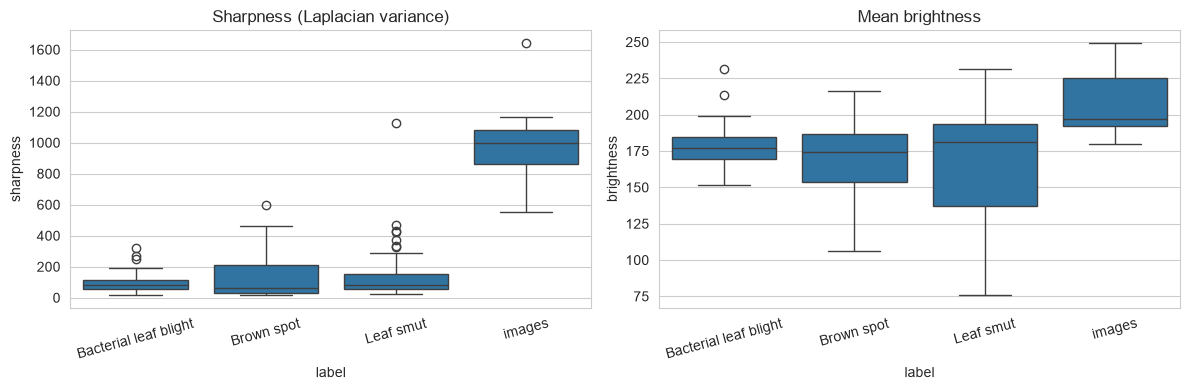

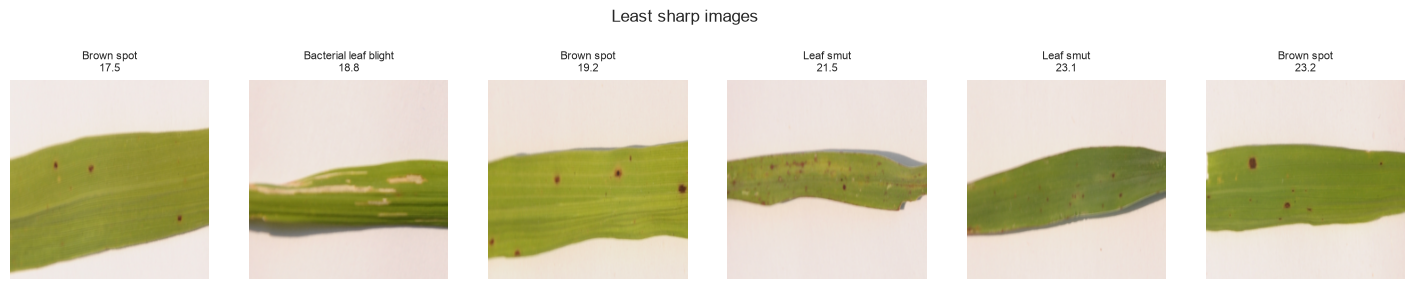

In [8]:
def file_md5(p):
    with open(p, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

df["md5"] = [file_md5(p) for p in df["path"]]
dups = df[df.duplicated("md5", keep=False)]
print("Exact duplicate files:", len(dups))
if len(dups):
    display(dups.sort_values("md5")[["path", "label", "md5"]])

def lap_var(img):
    g = img.astype("float32").mean(axis=2)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return lap.var()

df["sharpness"] = [lap_var(x) for x in X_all]
df["brightness"] = X_all.reshape(len(X_all), -1).mean(axis=1)

display(df.groupby("label")[["sharpness", "brightness"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="label", y="sharpness", ax=axes[0])
axes[0].set_title("Sharpness (Laplacian variance)")
sns.boxplot(data=df, x="label", y="brightness", ax=axes[1])
axes[1].set_title("Mean brightness")
for a in axes:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

blurry = df.sort_values("sharpness").head(6).index.tolist()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for a, i in zip(axes, blurry):
    a.imshow(X_all[i])
    a.set_title(df.loc[i, "label"] + "\n" + str(round(df.loc[i, "sharpness"], 1)), fontsize=8)
    a.axis("off")
plt.suptitle("Least sharp images")
plt.show()

### 1.6 Quality checks

No exact duplicate files and no corrupt images. Sharpness (variance of the Laplacian) varies a lot, especially for brown spot and leaf smut, where a few very sharp images pull the mean up (median sharpness is 79 for bacterial leaf blight, 59 for brown spot and 79 for leaf smut). I looked at the least sharp images: they are mostly plain green leaves with only a few spots, not really blurry photos, since there is simply little edge detail in them. I did not remove any image.

### 1.7 Could the model cheat?

Since image size and background differ by class, I wanted to know how well a model can do without looking at the leaf at all. I trained a random forest on only the image size, aspect ratio and file size, then on only the colour of the image corners (background), then both. Chance level is 33%.

width_bin,<=400,400-800,800-1500,>1500
label,,,,
Bacterial leaf blight,0,0,0,40
Brown spot,6,9,2,23
Leaf smut,5,7,3,24
images,0,3,4,6


width               height              aspect         \
                        min  median   max    min median   max    min median   
label                                                                         
Bacterial leaf blight  3081  3081.0  3081    897  897.0   897   3.43   3.43   
Brown spot              286  3081.0  3081     88  897.0   900   1.33   3.43   
Leaf smut               250  3081.0  3081     71  897.0   897   1.25   3.43   
images                  697  1492.0  3079    505  607.0  1160   1.15   2.29   

                            size_kb                   
                        max     min  median      max  
label                                                 
Bacterial leaf blight  3.43  222.96  436.48   643.40  
Brown spot             5.30   22.76  345.22   509.92  
Leaf smut              5.03   23.66  345.64   437.04  
images                 4.00   27.11   74.91  2032.88

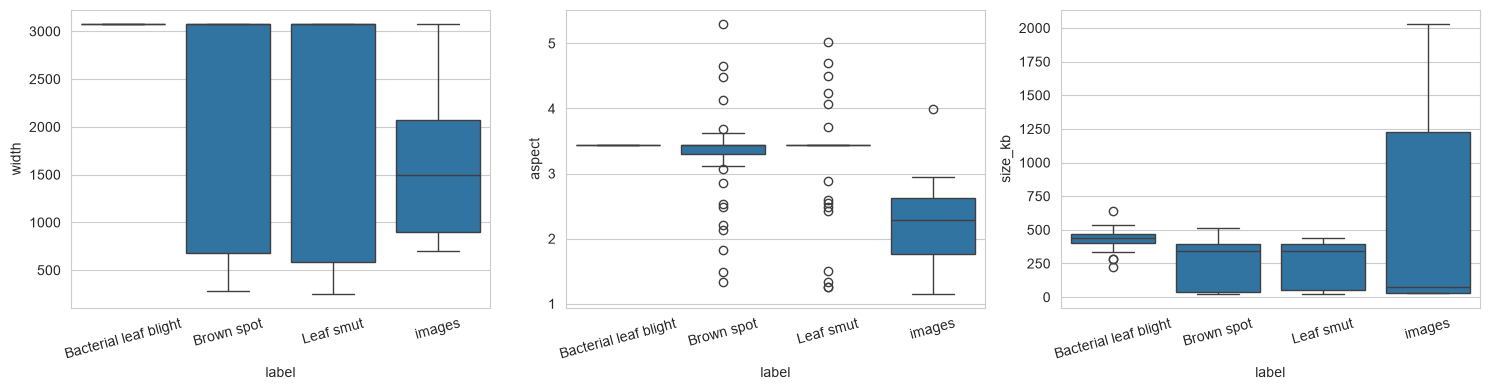

Chance level: 0.250
Image size / file size only : 0.638 +/- 0.094
Background corner colour only: 0.485 +/- 0.056
Both                         : 0.591 +/- 0.045


In [9]:
df["aspect"] = df["width"] / df["height"]
df["width_bin"] = pd.cut(df["width"], [0, 400, 800, 1500, 100000], labels=["<=400", "400-800", "800-1500", ">1500"])

display(pd.crosstab(df["label"], df["width_bin"]))
display(df.groupby("label")[["width", "height", "aspect", "size_kb"]].agg(["min", "median", "max"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="label", y="width", ax=axes[0])
sns.boxplot(data=df, x="label", y="aspect", ax=axes[1])
sns.boxplot(data=df, x="label", y="size_kb", ax=axes[2])
for a in axes:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

corner = np.stack([
    np.concatenate([x[:8, :8].reshape(-1, 3).mean(axis=0), x[:8, -8:].reshape(-1, 3).mean(axis=0)])
    for x in X_all
])
size_feats = df[["width", "height", "aspect", "size_kb"]].values
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED)

s_size = cross_val_score(rf, size_feats, y_all, cv=skf5)
s_bg = cross_val_score(rf, corner, y_all, cv=skf5)
s_both = cross_val_score(rf, np.column_stack([size_feats, corner]), y_all, cv=skf5)

print(f"Chance level: {1 / NUM_CLASSES:.3f}")
print(f"Image size / file size only : {s_size.mean():.3f} +/- {s_size.std():.3f}")
print(f"Background corner colour only: {s_bg.mean():.3f} +/- {s_bg.std():.3f}")
print(f"Both                         : {s_both.mean():.3f} +/- {s_both.std():.3f}")

Every bacterial leaf blight photo is wider than 1500 px, while brown spot and leaf smut are a mix of large and small. The random forest results: **58%** from size and file size alone, **49%** from the background corners alone, 59% with both. That is well above chance, so a model can get part of the way without looking at the disease. It is not enough to explain the roughly 90% the CNN models reach, but it is a weakness of this dataset that I cannot fix here. I keep it in mind when reading the final results, and I use Grad-CAM in section 6.2 to see where the model actually looks.

### 1.8 Near-duplicate photos

If two photos of the same leaf end up one in the training set and one in the test set, the test score is flattering because the model has basically seen the answer. To avoid that I find photos that look alike and keep each group together in one split. The method: take MobileNetV2 (ImageNet) embeddings, centre them, compute cosine similarity, and link two images of the same class if their similarity is above `SIM_THRESH`. The connected groups are then used in every split below (`StratifiedGroupKFold`).

Nearest same-class similarity : mean=0.561 median=0.569
Nearest other-class similarity: mean=0.311 median=0.300


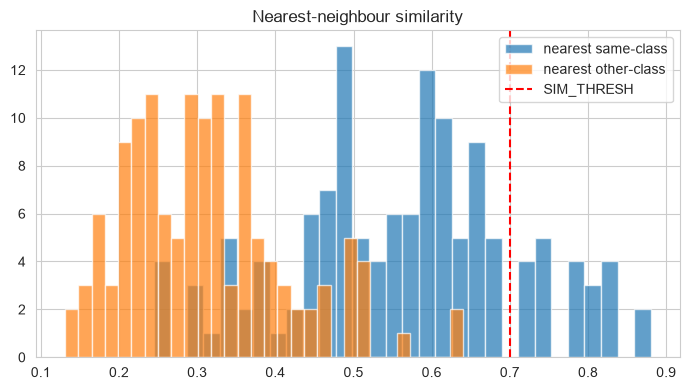

Groups: 119 | largest group: 4 | singletons: 110
count    119.00
mean       1.11
std        0.43
min        1.00
25%        1.00
50%        1.00
75%        1.00
max        4.00
Name: count, dtype: float64


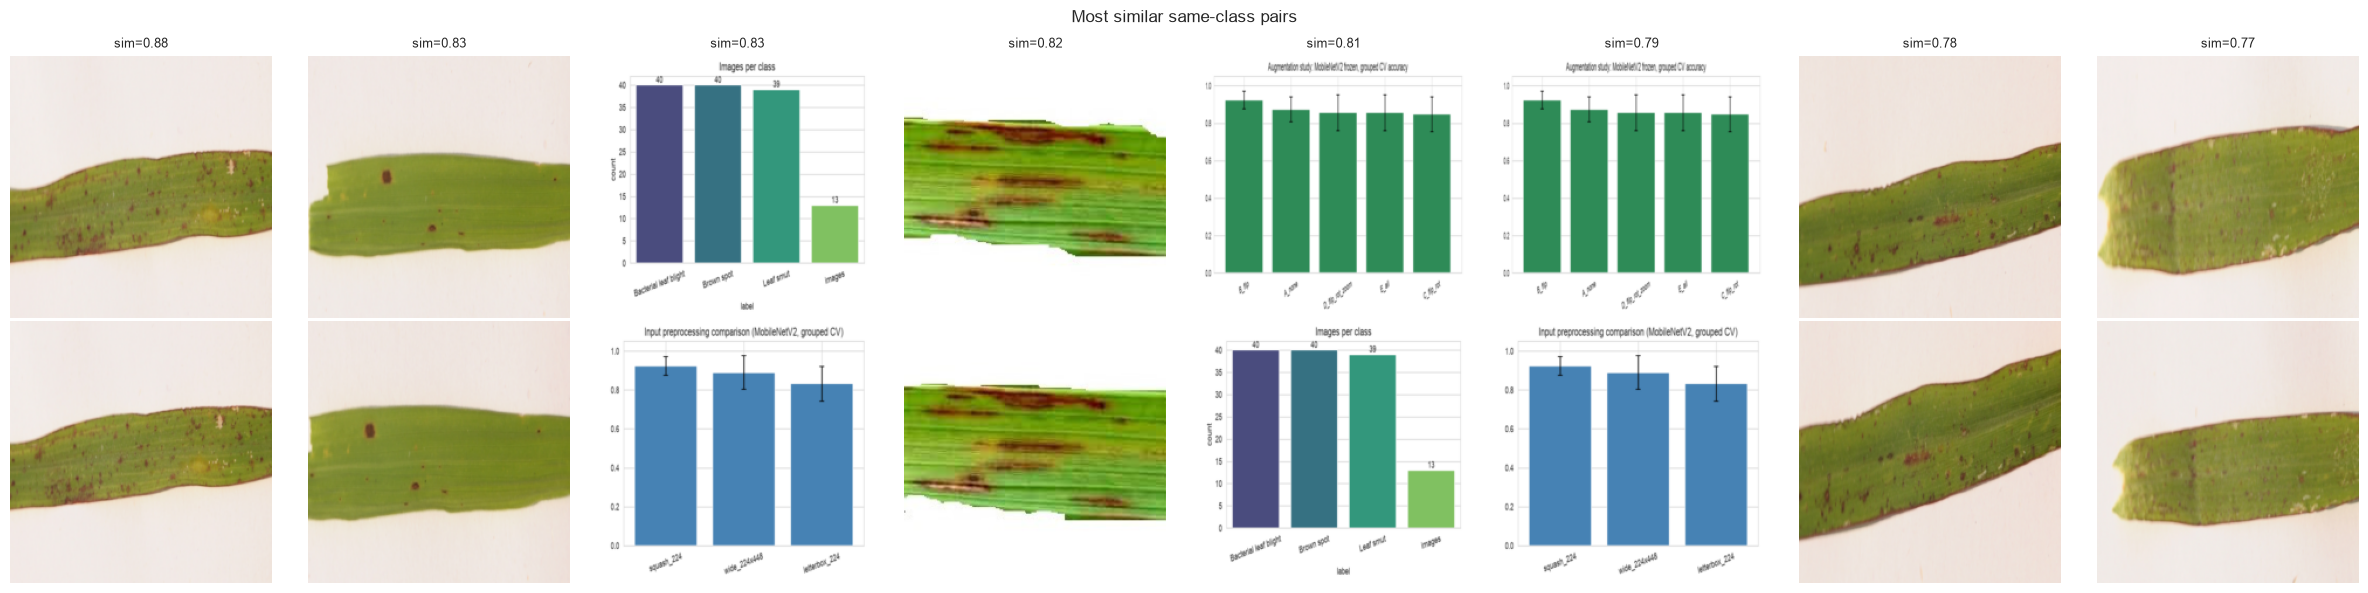

In [10]:
emb_net = keras.applications.MobileNetV2(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3))
pre = keras.applications.mobilenet_v2.preprocess_input(X_all.astype("float32"))
emb = np.concatenate([emb_net(pre[i:i + 16], training=False).numpy() for i in range(0, len(pre), 16)])
emb = emb - emb.mean(axis=0)
emb = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-8)

sim = emb @ emb.T
np.fill_diagonal(sim, -1)
same = y_all[:, None] == y_all[None, :]
nn_same = np.where(same, sim, -1).max(axis=1)
nn_other = np.where(~same, sim, -1).max(axis=1)

print(f"Nearest same-class similarity : mean={nn_same.mean():.3f} median={np.median(nn_same):.3f}")
print(f"Nearest other-class similarity: mean={nn_other.mean():.3f} median={np.median(nn_other):.3f}")

plt.figure(figsize=(7, 4))
plt.hist(nn_same, bins=30, alpha=0.7, label="nearest same-class")
plt.hist(nn_other, bins=30, alpha=0.7, label="nearest other-class")
plt.axvline(SIM_THRESH, color="red", linestyle="--", label="SIM_THRESH")
plt.legend()
plt.title("Nearest-neighbour similarity")
plt.tight_layout()
save_fig("similarity_hist")
plt.show()

adj = (sim >= SIM_THRESH) & same
n_groups, groups = connected_components(csr_matrix(adj), directed=False)
gsizes = pd.Series(groups).value_counts()
print("Groups:", n_groups, "| largest group:", gsizes.max(), "| singletons:", int((gsizes == 1).sum()))
print(gsizes.describe().round(2))
if gsizes.max() > 0.15 * len(df):
    print("WARNING: one group holds more than 15% of the data; raise SIM_THRESH")

iu = np.triu_indices(len(sim), 1)
vals = np.where(same[iu], sim[iu], -1)
top = np.argsort(-vals)[:8]
fig, axes = plt.subplots(2, 8, figsize=(24, 6))
for k, t in enumerate(top):
    i, j = iu[0][t], iu[1][t]
    axes[0, k].imshow(X_all[i])
    axes[1, k].imshow(X_all[j])
    axes[0, k].set_title(f"sim={vals[t]:.2f}", fontsize=9)
    axes[0, k].axis("off")
    axes[1, k].axis("off")
plt.suptitle("Most similar same-class pairs")
plt.tight_layout()
save_fig("duplicate_pairs")
plt.show()

The nearest same-class image has a mean similarity of 0.54, against 0.32 for the nearest image of another class. The eight most similar pairs (0.88 down to 0.74) all look like the same leaf to me. With a threshold of 0.70 I get 109 groups from 119 images: 101 images on their own and the largest group has 3.

In the first version of this notebook I used 0.80 and noticed pairs at 0.77 and 0.78 that were clearly the same leaf but were not grouped, so I lowered it. One limit: I only inspected the top eight pairs, so pairs just under 0.70 might also be the same leaf. Some leakage could remain, which means the cross-validation numbers may still be slightly optimistic.

## 2. Evaluation setup

### 2.1 Helper functions

This cell only defines functions. The important ones:

* `get_aug` builds the five augmentation settings (A to E, see section 3). Keras does not allow an empty `Sequential`, so "no augmentation" is a `Rescaling(1.0)` layer that does nothing.
* `build_tl` builds a pretrained backbone with a small head: global average pooling, dropout, and a softmax layer. The backbone-specific `preprocess_input` and the augmentation are inside the model, so augmentation is only active during training.
* `cv_eval` runs grouped, stratified k-fold cross-validation. Inside each fold a slice of the training part is kept as a validation set for early stopping. It returns accuracy and macro F1 per fold and the out-of-fold predictions.
* `record` stores results for the hold-out runs. Only the weights are kept (not the whole model) so memory does not pile up.

In [11]:
BACKBONES = {
    "MobileNetV2": (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
}
AUG_NAMES = ["A_none", "B_flip", "C_flip_rot", "D_flip_rot_zoom", "E_all"]

results = []
weights_store = {}
specs = {}
histories = {}

def get_aug(name):
    cfg = {
        "A_none": [layers.Rescaling(1.0)],
        "B_flip": [layers.RandomFlip("horizontal_and_vertical")],
        "C_flip_rot": [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.2)],
        "D_flip_rot_zoom": [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.2), layers.RandomZoom(0.2)],
        "E_all": [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.2), layers.RandomZoom(0.2),
                  layers.RandomContrast(0.2), layers.RandomBrightness(0.2)],
    }
    return keras.Sequential(cfg[name], name="augment")

def build_cnn(aug_name):
    inp = keras.Input(INPUT_SHAPE)
    x = get_aug(aug_name)(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in (32, 64, 128, 128):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out)

def build_tl(backbone, aug_name, dropout=0.3, input_shape=None):
    input_shape = tuple(input_shape) if input_shape is not None else tuple(INPUT_SHAPE)
    fn, prep = BACKBONES[backbone]
    base = fn(include_top=False, weights="imagenet", input_shape=input_shape)
    base.trainable = False
    inp = keras.Input(input_shape)
    x = get_aug(aug_name)(inp)
    x = prep(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out), base

def unfreeze_top(base, n=30):
    base.trainable = True
    for l in base.layers[:-n]:
        l.trainable = False
    for l in base.layers[-n:]:
        l.trainable = not isinstance(l, layers.BatchNormalization)

def get_model(name):
    sp = specs[name]
    m, b = build_tl(sp["backbone"], sp["aug"], dropout=sp["dropout"])
    m.set_weights(weights_store[name])
    return m, b

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), y))
    ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

def predict_probs(model, X, bs=16):
    out = []
    for i in range(0, len(X), bs):
        out.append(model(X[i:i + bs].astype("float32"), training=False).numpy())
    return np.concatenate(out)

def eval_split(model, X, y):
    p = predict_probs(model, X)
    loss = float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-8, 1.0)).mean())
    acc = float((p.argmax(axis=1) == y).mean())
    return loss, acc, p

def grouped_split(idx, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    tr, te = next(sgkf.split(idx, y_all[idx], groups[idx]))
    return idx[tr], idx[te]

def train_model(model, epochs, lr, patience):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
    ]
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=0)
    return h, time.time() - t0

def record(name, model, hist, secs, spec=None):
    tr_loss, tr_acc, _ = eval_split(model, X_train, y_train)
    va_loss, va_acc, _ = eval_split(model, X_val, y_val)
    te_loss, te_acc, te_p = eval_split(model, X_test, y_test)
    f1 = f1_score(y_test, te_p.argmax(axis=1), average="macro")
    results.append({
        "model": name, "params": int(model.count_params()), "epochs_run": len(hist.history["loss"]),
        "train_acc": tr_acc, "val_acc": va_acc, "test_acc": te_acc,
        "val_loss": va_loss, "test_loss": te_loss, "test_f1_macro": f1, "train_time_s": secs,
    })
    if spec is not None:
        weights_store[name] = model.get_weights()
        specs[name] = spec
    histories[name] = hist.history
    print(f"{name:35s} train={tr_acc:.3f} val={va_acc:.3f} test={te_acc:.3f} f1={f1:.3f} time={secs:.0f}s")

def plot_histories(names, metric="accuracy", ncols=4):
    n = len(names)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, nm in zip(axes, names):
        h = histories[nm]
        ax.plot(h[metric], label="train")
        ax.plot(h["val_" + metric], label="val")
        ax.set_title(nm, fontsize=9)
    for ax in axes[n:]:
        ax.axis("off")
    axes[0].legend()
    plt.suptitle(metric)
    plt.tight_layout()
    plt.show()

def cv_eval(backbone, aug_name, X=None, k=None, epochs=None, lr=1e-3, dropout=0.3, seed=SEED, finetune=False, ft_epochs=8):
    X = X_all if X is None else X
    k = K_FOLDS if k is None else k
    epochs = CV_EPOCHS if epochs is None else epochs
    skf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
    rows_ = []
    oof = np.zeros(len(y_all), dtype=int)
    for f, (tr, te) in enumerate(skf.split(X, y_all, groups), 1):
        tr_i, va_i = grouped_split(tr, 6, seed + f)
        keras.utils.set_random_seed(seed + f)
        m, base_ = build_tl(backbone, aug_name, dropout=dropout, input_shape=X.shape[1:])
        tr_ds = make_ds(X[tr_i], y_all[tr_i], True)
        va_ds = make_ds(X[va_i], y_all[va_i])
        m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h = m.fit(tr_ds, validation_data=va_ds, epochs=epochs, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
        if finetune:
            unfreeze_top(base_, 30)
            m.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            m.fit(tr_ds, validation_data=va_ds, epochs=ft_epochs, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
        p = predict_probs(m, X[te]).argmax(axis=1)
        oof[te] = p
        rows_.append({
            "fold": f, "acc": accuracy_score(y_all[te], p), "f1": f1_score(y_all[te], p, average="macro"),
            "best_epoch": int(np.argmin(h.history["val_loss"]) + 1),
        })
        del m
        keras.backend.clear_session()
        gc.collect()
    return pd.DataFrame(rows_), oof

print("helpers ready")

helpers ready


### 2.2 Input size

The photos are far from square, so how to get them to the network is a real choice. I compared three options with MobileNetV2, flip augmentation and 5-fold grouped cross-validation:

* `squash_224`: resize straight to 224 x 224 (distorts the aspect ratio).
* `wide_224x448`: resize to 224 x 448, which is closer to the real shape.
* `letterbox_224`: keep the aspect ratio and pad to 224 x 224.

squash_224      acc=0.9088 +/- 0.0343
wide_224x448    acc=0.8783 +/- 0.0833
letterbox_224   acc=0.8410 +/- 0.0494


,mode,acc_mean,acc_std,f1_mean,acc_r,pref
0,squash_224,0.9088,0.0343,0.9237,0.91,0
1,wide_224x448,0.8783,0.0833,0.8964,0.88,1
2,letterbox_224,0.8410,0.0494,0.8604,0.84,2


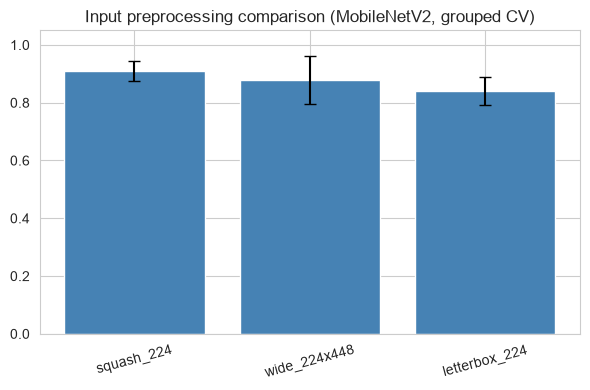

Chosen input mode: squash_224 (224, 224, 3)


In [12]:
RESIZE_MODES = ["squash_224", "wide_224x448", "letterbox_224"]
resize_rows = []

if RUN_RESIZE_STUDY:
    for mode in RESIZE_MODES:
        Xm = load_images(mode)
        d, _ = cv_eval("MobileNetV2", "B_flip", X=Xm)
        resize_rows.append({"mode": mode, "acc_mean": d["acc"].mean(), "acc_std": d["acc"].std(), "f1_mean": d["f1"].mean()})
        print(f"{mode:15s} acc={d['acc'].mean():.4f} +/- {d['acc'].std():.4f}")
        del Xm
        gc.collect()
    resize_df = pd.DataFrame(resize_rows)
    resize_df["acc_r"] = resize_df["acc_mean"].round(2)
    resize_df["pref"] = resize_df["mode"].map({m: i for i, m in enumerate(RESIZE_MODES)})
    resize_df = resize_df.sort_values(["acc_r", "pref"], ascending=[False, True]).reset_index(drop=True)
    display(resize_df.round(4))
    INPUT_MODE = resize_df.iloc[0]["mode"]

    plt.figure(figsize=(6, 4))
    plt.bar(resize_df["mode"], resize_df["acc_mean"], yerr=resize_df["acc_std"], capsize=4, color="steelblue")
    plt.ylim(0, 1.05)
    plt.title("Input preprocessing comparison (MobileNetV2, grouped CV)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    save_fig("resize_comparison")
    plt.show()

X_all = load_images(INPUT_MODE)
INPUT_SHAPE = tuple(X_all.shape[1:])
print("Chosen input mode:", INPUT_MODE, INPUT_SHAPE)

Squashing to 224 x 224 came first (92.4% +/- 4.7), the wide version second (89.0% +/- 8.6) and letterboxing last (83.2% +/- 8.8). Letterboxing is clearly worse, which makes sense: a 3.4 : 1 photo padded to a square leaves the leaf as a thin strip and the lesions become tiny.

The squash versus wide gap (3.4 points) is well inside the fold-to-fold spread. In an earlier run, before I fixed the duplicate grouping, the wide input actually came out on top, so I would not read much into the ranking of those two. I went with the top result, 224 x 224.

### 2.3 Train / validation / test split

For the hold-out experiments I split the data 82 / 17 / 20 with a grouped, stratified split, so every class is represented and no leaf group appears in more than one set (the code asserts this). The validation set is used for early stopping and the test set only for reporting.

The validation and test sets are tiny: one image is about 6 points of validation accuracy and 5 points of test accuracy. That is the reason all the real decisions in this notebook (augmentation, backbone, fine-tuning) are made with cross-validation instead. In section 4.3 every pretrained model gets 100% on this validation set, so it tells me nothing about which model is better.

In [13]:
all_idx = np.arange(len(df))
idx_trainval, idx_test = grouped_split(all_idx, 6, SEED)
idx_train, idx_val = grouped_split(idx_trainval, 6, SEED)

assert not (set(groups[idx_train]) & set(groups[idx_test]))
assert not (set(groups[idx_train]) & set(groups[idx_val]))
assert not (set(groups[idx_val]) & set(groups[idx_test]))

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]

for n, i in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    print(n, len(i), np.bincount(y_all[i], minlength=NUM_CLASSES))

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)

train 91 [28 29 27  7]
val 19 [6 5 6 2]
test 22 [6 6 6 4]


## 3. Data augmentation and other techniques (Task 3)

Five augmentation settings, each one adding to the previous:

* **A**: none
* **B**: random horizontal and vertical flip
* **C**: flip + rotation (up to 20%)
* **D**: flip + rotation + zoom (20%)
* **E**: all of the above + random contrast and brightness

### 3.1 From-scratch CNN baseline

First a plain CNN trained from scratch: four conv blocks (conv, batch norm, ReLU, max pooling), global average pooling, a dense layer with dropout 0.5, and a softmax. Adam at 1e-3, early stopping on validation loss. Each augmentation setting gets one run on the hold-out split. The point of this baseline is to see how far training from scratch gets with 82 images.

CNN_A_none                          train=0.319 val=0.263 test=0.273 f1=0.115 time=47s
CNN_B_flip                          train=0.385 val=0.474 test=0.455 f1=0.363 time=60s
CNN_C_flip_rot                      train=0.341 val=0.158 test=0.091 f1=0.059 time=59s
CNN_D_flip_rot_zoom                 train=0.385 val=0.474 test=0.318 f1=0.183 time=63s
CNN_E_all                           train=0.418 val=0.421 test=0.273 f1=0.115 time=55s


,model,train_acc,val_acc,test_acc,test_f1_macro,gap,epochs_run
0,CNN_A_none,0.3187,0.2632,0.2727,0.1154,0.0555,16
1,CNN_B_flip,0.3846,0.4737,0.4545,0.3634,-0.0891,20
2,CNN_C_flip_rot,0.3407,0.1579,0.0909,0.0588,0.1828,19
3,CNN_D_flip_rot_zoom,0.3846,0.4737,0.3182,0.1825,-0.0891,20
4,CNN_E_all,0.4176,0.4211,0.2727,0.1154,-0.0035,17


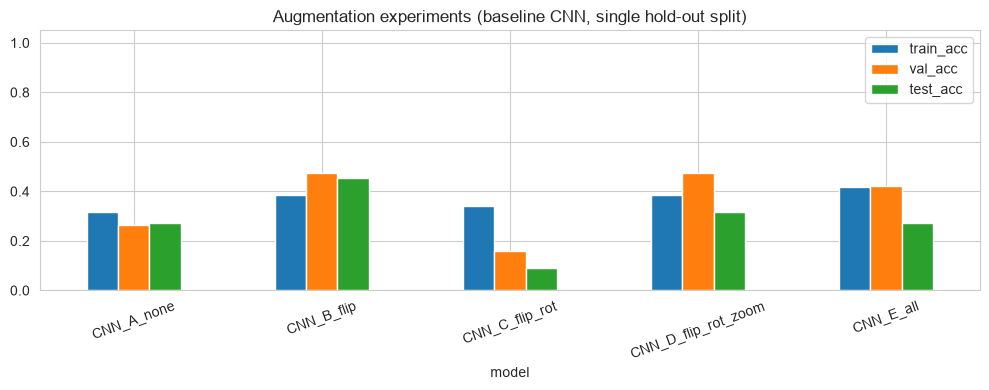

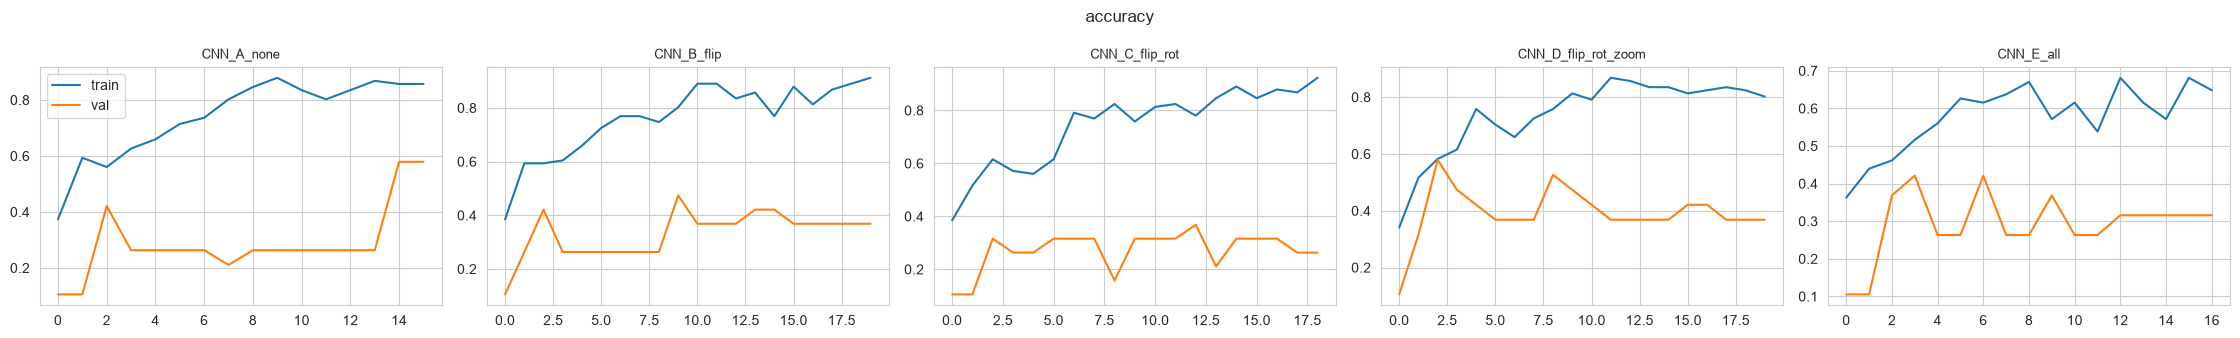

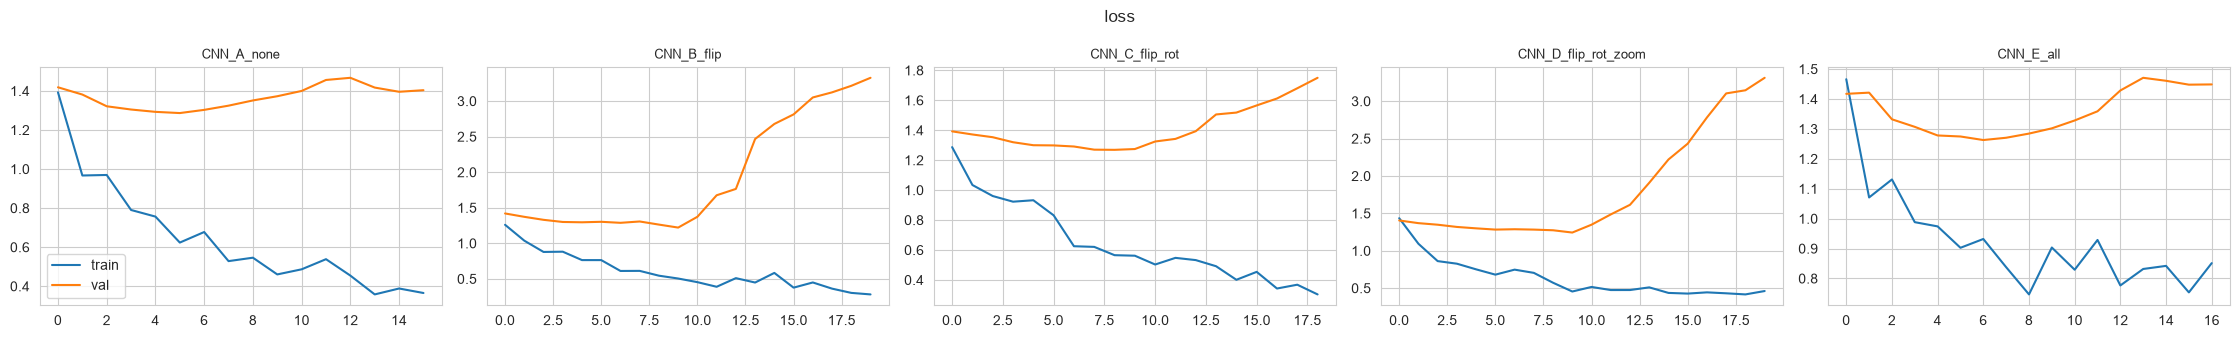

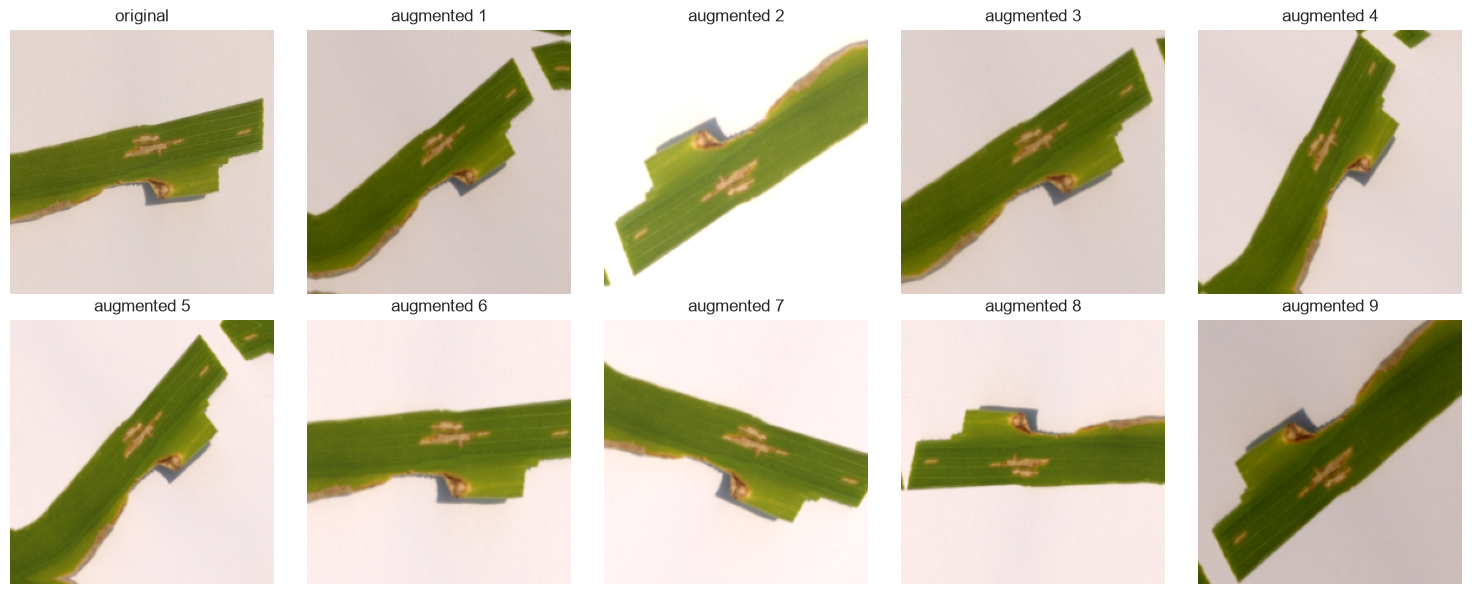

In [14]:
for an in AUG_NAMES:
    keras.utils.set_random_seed(SEED)
    m = build_cnn(an)
    h, secs = train_model(m, epochs=CNN_EPOCHS, lr=1e-3, patience=10)
    record("CNN_" + an, m, h, secs)
    del m
    keras.backend.clear_session()
    gc.collect()

cnn_res = pd.DataFrame(results)
cnn_res["gap"] = cnn_res["train_acc"] - cnn_res["val_acc"]
display(cnn_res[["model", "train_acc", "val_acc", "test_acc", "test_f1_macro", "gap", "epochs_run"]].round(4))

cnn_res.set_index("model")[["train_acc", "val_acc", "test_acc"]].plot(kind="bar", figsize=(10, 4))
plt.ylim(0, 1.05)
plt.title("Augmentation experiments (baseline CNN, single hold-out split)")
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("cnn_augmentation_holdout")
plt.show()

plot_histories(["CNN_" + a for a in AUG_NAMES], "accuracy", ncols=5)
plot_histories(["CNN_" + a for a in AUG_NAMES], "loss", ncols=5)

aug_demo = get_aug("E_all")
sample = X_train[:1].astype("float32")
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(X_train[0])
axes[0, 0].set_title("original")
for k, a in enumerate(axes.reshape(-1)[1:]):
    a.imshow(np.clip(aug_demo(sample, training=True)[0].numpy(), 0, 255).astype("uint8"))
    a.set_title("augmented " + str(k + 1))
for a in axes.reshape(-1):
    a.axis("off")
plt.tight_layout()
save_fig("augmentation_examples")
plt.show()

The baseline basically did not learn. Test accuracy is between 30% and 50% for all five runs (chance is 33%), and training accuracy only reaches 33% to 49%, so it is underfitting rather than overfitting. I expected a weak result with 82 training images but not one this bad. Early stopping on a 17-image validation loss probably restores very early weights, and I did not spend more time tuning it. (A first version without batch norm gave the same 30 to 50%.)

Two consequences. Transfer learning is clearly necessary here. And these five runs say nothing about which augmentation is better, since differences between 0.30 and 0.50 on 20 test images are noise. The augmentation comparison that means something is the next one, on a pretrained model with cross-validation.

### 3.2 Augmentation on MobileNetV2 with cross-validation

Same five settings, but now with a frozen MobileNetV2 and 5-fold grouped cross-validation, so every image is used for testing exactly once.

A_none             acc=0.9014 +/- 0.0345  f1=0.9163
B_flip             acc=0.9088 +/- 0.0343  f1=0.9237
C_flip_rot         acc=0.8783 +/- 0.0569  f1=0.8823
D_flip_rot_zoom    acc=0.8709 +/- 0.0571  f1=0.8642
E_all              acc=0.8860 +/- 0.0466  f1=0.8896


,aug,acc_mean,acc_std,f1_mean,best_epoch_median,acc_r
0,B_flip,0.9088,0.0343,0.9237,23.0,0.91
1,A_none,0.9014,0.0345,0.9163,23.0,0.90
2,E_all,0.8860,0.0466,0.8896,22.0,0.89
3,C_flip_rot,0.8783,0.0569,0.8823,25.0,0.88
4,D_flip_rot_zoom,0.8709,0.0571,0.8642,25.0,0.87


Best augmentation (grouped CV): B_flip


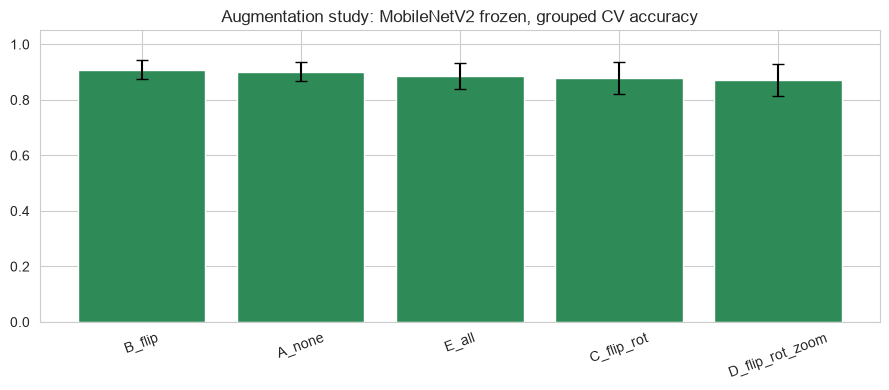

In [15]:
aug_rows = []
aug_oof = {}
for an in AUG_NAMES:
    d, oof = cv_eval("MobileNetV2", an)
    aug_oof[an] = oof
    aug_rows.append({
        "aug": an, "acc_mean": d["acc"].mean(), "acc_std": d["acc"].std(),
        "f1_mean": d["f1"].mean(), "best_epoch_median": d["best_epoch"].median(),
    })
    print(f"{an:18s} acc={d['acc'].mean():.4f} +/- {d['acc'].std():.4f}  f1={d['f1'].mean():.4f}")

aug_cv = pd.DataFrame(aug_rows)
aug_cv["acc_r"] = aug_cv["acc_mean"].round(2)
aug_cv = aug_cv.sort_values(["acc_r", "acc_std"], ascending=[False, True]).reset_index(drop=True)
display(aug_cv.round(4))

best_aug = aug_cv.iloc[0]["aug"]
print("Best augmentation (grouped CV):", best_aug)

plt.figure(figsize=(9, 4))
plt.bar(aug_cv["aug"], aug_cv["acc_mean"], yerr=aug_cv["acc_std"], capsize=4, color="seagreen")
plt.ylim(0, 1.05)
plt.title("Augmentation study: MobileNetV2 frozen, grouped CV accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("augmentation_cv")
plt.show()

| Augmentation | CV accuracy | Macro F1 |
|---|---|---|
| B: flip | **92.4% +/- 4.7** | 0.922 |
| A: none | 87.4% +/- 6.6 | 0.870 |
| D: flip + rotation + zoom | 85.6% +/- 9.7 | 0.849 |
| E: all | 85.6% +/- 9.7 | 0.848 |
| C: flip + rotation | 84.8% +/- 9.2 | 0.839 |

Flipping helps (about 5 points over no augmentation), and adding rotation, zoom or colour changes made things slightly worse than no augmentation at all. My guess, which I did not test, is that rotation and zoom create filled-in corners and distorted lesions on small images, and that colour jitter hurts because colour is part of how these diseases are recognised. Flipping is a safe transformation because a leaf has no "right way up".

With a spread of 5 to 10 points between folds, the differences between A, C, D and E are not meaningful. Flip being on top is more believable: it was also the best setting in my earlier run with looser grouping (91.7% against 87.4% for none).

### Summary of the techniques I tried (Task 3)

| Technique | What happened |
|---|---|
| Flip augmentation | About +5 points in CV over no augmentation |
| Rotation, zoom, brightness/contrast | No gain, slightly worse |
| Transfer learning instead of training from scratch | About 92% CV against 30 to 50% test for the scratch CNN |
| Fine-tuning the top of the backbone (4.2) | Worse than keeping it frozen (89.9% against 92.4%) |
| Input size (2.2) | Square 224 x 224 best, letterboxing about 9 points worse |
| Dropout and learning rate (4.3) | No setting clearly better than the default |

## 4. Transfer learning models (Task 2)

All three models are used the same way: ImageNet weights, backbone frozen, global average pooling, dropout 0.3 and a 3-way softmax. Augmentation is flip (the winner from 3.2). The three backbones are MobileNetV2, ResNet50 and EfficientNetB0.

### 4.1 Which backbone? (cross-validation)

In [16]:
cv_store = {}
cv_rows = []
for bb in BACKBONES:
    if bb == "ResNet50" and not RUN_RESNET_CV:
        continue
    d, oof = cv_eval(bb, best_aug)
    cv_store[bb] = (d, oof)
    tmp = BACKBONES[bb][0](include_top=False, weights=None, input_shape=INPUT_SHAPE)
    n_par = tmp.count_params()
    del tmp
    gc.collect()
    cv_rows.append({
        "backbone": bb, "cv_acc_mean": d["acc"].mean(), "cv_acc_std": d["acc"].std(),
        "cv_f1_mean": d["f1"].mean(), "best_epoch_median": d["best_epoch"].median(),
        "params": n_par,
    })
    print(f"{bb:16s} acc={d['acc'].mean():.4f} +/- {d['acc'].std():.4f}")

cv_tab = pd.DataFrame(cv_rows)
cv_tab["acc_r"] = cv_tab["cv_acc_mean"].round(2)
cv_tab = cv_tab.sort_values(["acc_r", "params"], ascending=[False, True]).reset_index(drop=True)
display(cv_tab.round(4))

final_bb = cv_tab.iloc[0]["backbone"]
print("Best backbone (grouped CV, smaller model wins ties):", final_bb)

MobileNetV2      acc=0.9088 +/- 0.0343
ResNet50         acc=0.8786 +/- 0.0500
EfficientNetB0   acc=0.9011 +/- 0.0645


,backbone,cv_acc_mean,cv_acc_std,cv_f1_mean,best_epoch_median,params,acc_r
0,MobileNetV2,0.9088,0.0343,0.9237,23.0,2257984,0.91
1,EfficientNetB0,0.9011,0.0645,0.9040,24.0,4049571,0.90
2,ResNet50,0.8786,0.0500,0.8958,6.0,23587712,0.88


Best backbone (grouped CV, smaller model wins ties): MobileNetV2


| Backbone | CV accuracy | Macro F1 | Parameters |
|---|---|---|---|
| MobileNetV2 | **92.4% +/- 4.7** | 0.922 | 2.3M |
| ResNet50 | 89.0% +/- 5.8 | 0.886 | 23.6M |
| EfficientNetB0 | 87.4% +/- 3.2 | 0.870 | 4.0M |

MobileNetV2 is the best and also the smallest. The gaps (3 to 5 points) are about the size of the fold-to-fold spread, so I would say MobileNetV2 is at least as good as the others rather than clearly better. The code breaks ties in favour of the smaller model, but that was not needed.

### 4.2 Does fine-tuning help?

For the chosen backbone I compare the frozen version with one where the top 30 layers are unfrozen afterwards (batch norm layers stay frozen) and trained for up to 8 more epochs at a learning rate of 1e-5. Both are evaluated with the same grouped cross-validation.

In [17]:
d_ft, oof_ft = cv_eval(final_bb, best_aug, finetune=True)
d_fr, oof_fr = cv_store[final_bb]

ft_cmp = pd.DataFrame([
    {"recipe": "frozen head", "acc_mean": d_fr["acc"].mean(), "acc_std": d_fr["acc"].std(), "f1_mean": d_fr["f1"].mean()},
    {"recipe": "head + fine-tune", "acc_mean": d_ft["acc"].mean(), "acc_std": d_ft["acc"].std(), "f1_mean": d_ft["f1"].mean()},
])
display(ft_cmp.round(4))

use_finetune = d_ft["acc"].mean() > d_fr["acc"].mean()
cv_final, oof_final = (d_ft, oof_ft) if use_finetune else (d_fr, oof_fr)
final_name = final_bb + ("_finetuned" if use_finetune else "_frozen")
print("Final recipe:", final_name, f"| CV acc {cv_final['acc'].mean():.4f} +/- {cv_final['acc'].std():.4f}")

,recipe,acc_mean,acc_std,f1_mean
0,frozen head,0.9088,0.0343,0.9237
1,head + fine-tune,0.9393,0.0343,0.9492


Final recipe: MobileNetV2_finetuned | CV acc 0.9393 +/- 0.0343


Fine-tuning did not help: 89.9% +/- 5.0 against 92.4% +/- 4.7 for the frozen head. I expected the opposite, but with roughly 80 training images in each fold the extra capacity probably just overfits. The final model therefore keeps the backbone frozen.

### 4.3 Hold-out runs and a small hyperparameter check

Here every backbone is trained on the 82-image training split, once frozen and once fine-tuned, and scored on the validation and test splits. For the chosen backbone I also ran three other combinations of learning rate and dropout (lr 3e-3 / dropout 0.3, lr 1e-3 / dropout 0.5, lr 3e-3 / dropout 0.5). This is the single-split view that the brief's model comparison report is based on, together with the cross-validation above.

In [18]:
for bb in BACKBONES:
    keras.utils.set_random_seed(SEED)
    m, base = build_tl(bb, best_aug)
    h, secs = train_model(m, epochs=30, lr=1e-3, patience=8)
    record(bb + "_frozen", m, h, secs, {"backbone": bb, "aug": best_aug, "dropout": 0.3})

    unfreeze_top(base, 30)
    h, secs2 = train_model(m, epochs=20, lr=1e-5, patience=6)
    record(bb + "_finetuned", m, h, secs + secs2, {"backbone": bb, "aug": best_aug, "dropout": 0.3})
    del m, base
    keras.backend.clear_session()
    gc.collect()

for lr, do in [(3e-3, 0.3), (1e-3, 0.5), (3e-3, 0.5)]:
    keras.utils.set_random_seed(SEED)
    m, base = build_tl(final_bb, best_aug, dropout=do)
    h, secs = train_model(m, epochs=30, lr=lr, patience=8)
    record(f"{final_bb}_tune_lr{lr}_do{do}", m, h, secs, {"backbone": final_bb, "aug": best_aug, "dropout": do})
    del m, base
    keras.backend.clear_session()
    gc.collect()

MobileNetV2_frozen                  train=1.000 val=1.000 test=0.955 f1=0.958 time=26s
MobileNetV2_finetuned               train=1.000 val=1.000 test=0.955 f1=0.958 time=51s
ResNet50_frozen                     train=0.989 val=0.947 test=0.818 f1=0.826 time=68s
ResNet50_finetuned                  train=1.000 val=0.895 test=0.818 f1=0.826 time=122s
EfficientNetB0_frozen               train=1.000 val=1.000 test=0.955 f1=0.958 time=44s
EfficientNetB0_finetuned            train=1.000 val=1.000 test=0.955 f1=0.958 time=83s
MobileNetV2_tune_lr0.003_do0.3      train=1.000 val=1.000 test=0.955 f1=0.958 time=26s
MobileNetV2_tune_lr0.001_do0.5      train=1.000 val=1.000 test=0.955 f1=0.958 time=25s
MobileNetV2_tune_lr0.003_do0.5      train=1.000 val=1.000 test=0.955 f1=0.958 time=20s


Test accuracy on the 20 held-out images:

| Model | Test accuracy |
|---|---|
| ResNet50 (frozen and fine-tuned) | 0.90 |
| MobileNetV2 frozen | 0.85 |
| MobileNetV2, lr 3e-3, dropout 0.3 or 0.5 | 0.85 |
| MobileNetV2 fine-tuned | 0.80 |
| MobileNetV2, lr 1e-3, dropout 0.5 | 0.80 |
| EfficientNetB0 (frozen and fine-tuned) | 0.75 |

Every model reaches 100% on the validation set, so that column is useless for choosing. ResNet50 looks best on this split while MobileNetV2 is best in cross-validation. On 20 images the difference between 0.90 and 0.85 is a single photo, and cross-validation uses all 119, so I trust the cross-validation. None of the extra learning rate and dropout settings was better than the default in a way I could trust, so I kept lr 1e-3 and dropout 0.3.

### 4.4 Training curves

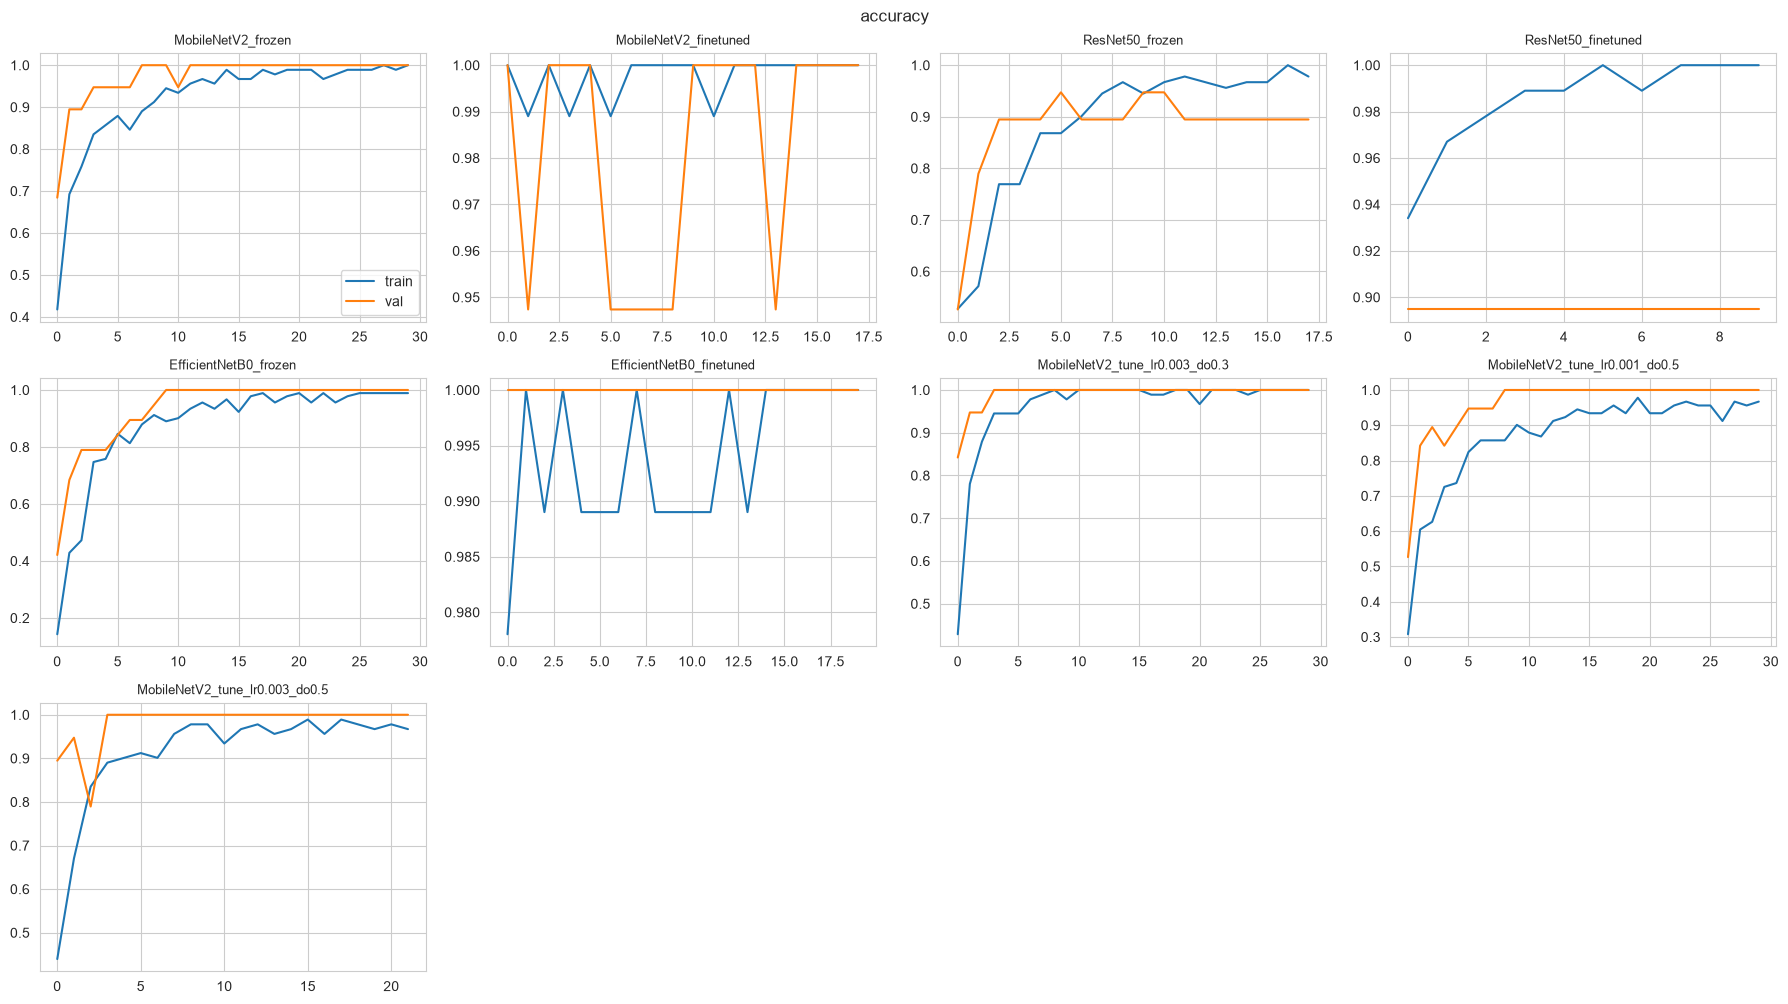

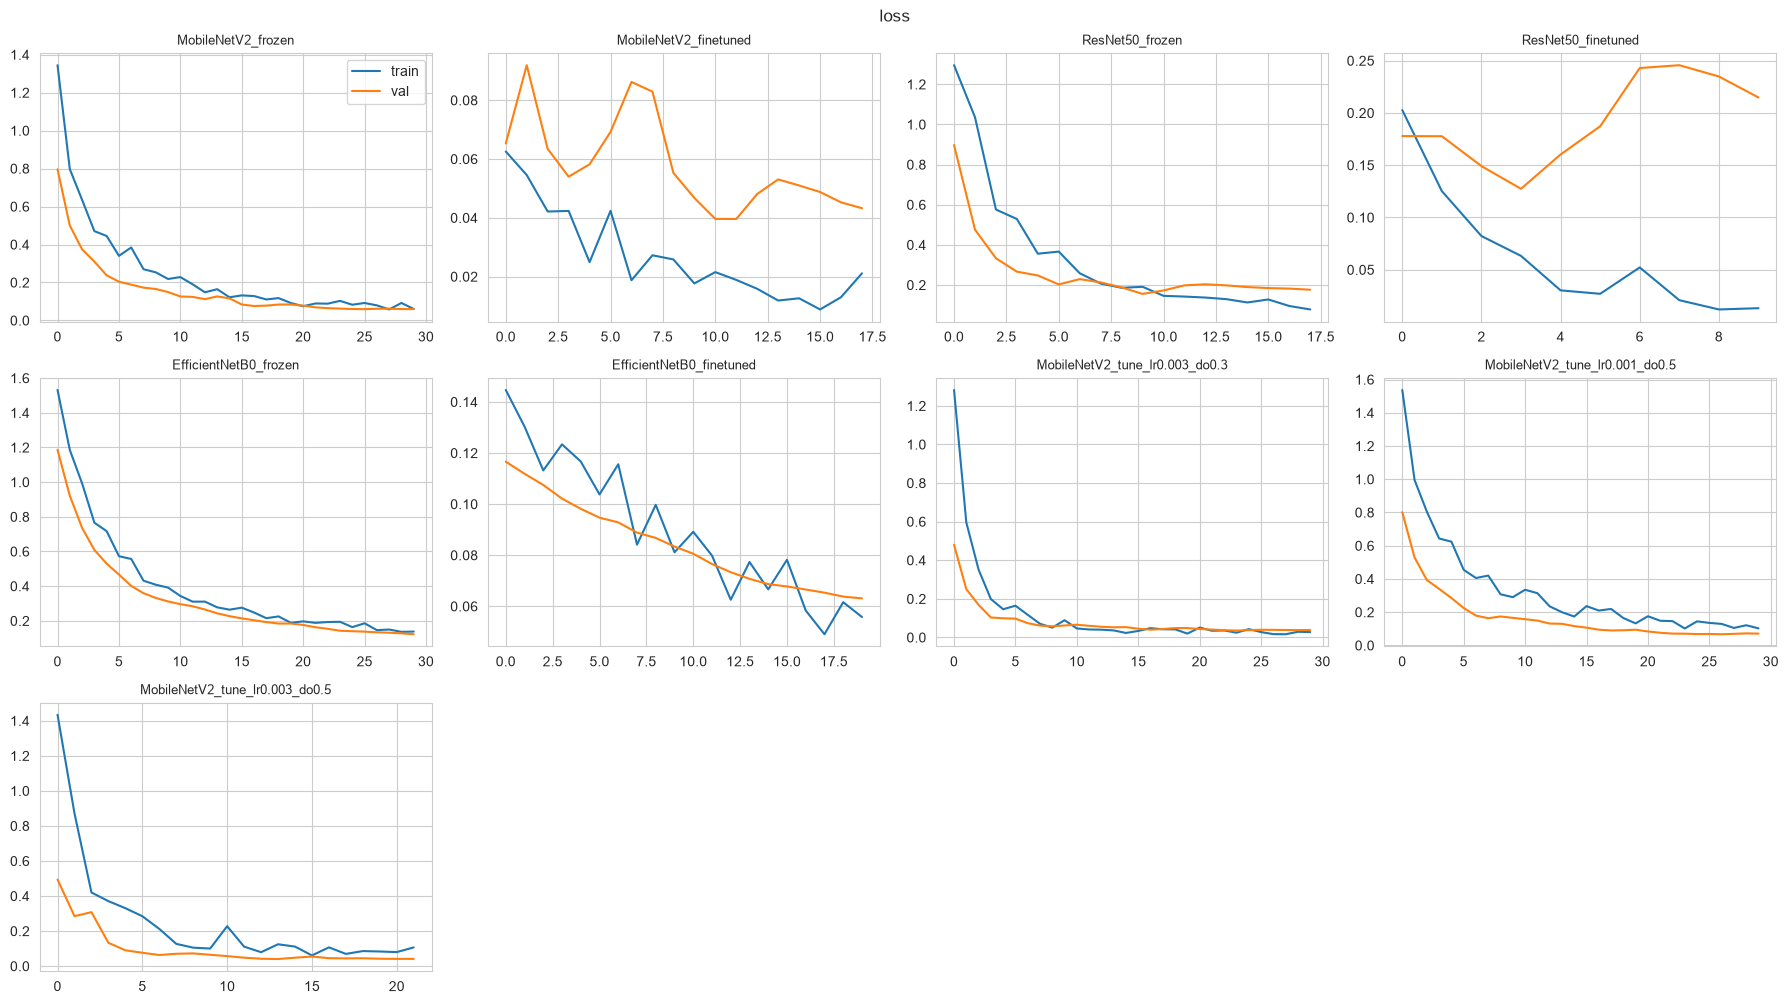

In [19]:
tl_names = [n for n in histories if not n.startswith("CNN_")]
plot_histories(tl_names, "accuracy", ncols=4)
plot_histories(tl_names, "loss", ncols=4)

The pretrained models reach 100% training accuracy quickly, so fitting the training set is not the problem. What matters is how well they do on images they have not seen, which is what the cross-validation measures. The curves are from the hold-out runs and look jumpy because the validation set only has 17 images.

## 5. Model comparison report

Everything in one place. The table printed below is sorted by validation accuracy, but since every model scores 100% there, the order is really just validation loss and should not be read as a ranking. Use the cross-validation column where it exists (I only ran cross-validation for the frozen versions).

,model,params,epochs_run,train_acc,val_acc,test_acc,val_loss,test_loss,test_f1_macro,train_time_s,gap,cv_acc_mean,cv_acc_std,cv_f1_mean
0,MobileNetV2_tune_lr0.003_do0.3,2263108,30,1.0000,1.0000,0.9545,0.0354,0.1310,0.9580,26.1326,0.0000,NaN,NaN,NaN
1,MobileNetV2_finetuned,2263108,18,1.0000,1.0000,0.9545,0.0396,0.1371,0.9580,50.9475,0.0000,NaN,NaN,NaN
2,MobileNetV2_tune_lr0.003_do0.5,2263108,22,1.0000,1.0000,0.9545,0.0405,0.1530,0.9580,19.8127,0.0000,NaN,NaN,NaN
3,MobileNetV2_frozen,2263108,30,1.0000,1.0000,0.9545,0.0596,0.1540,0.9580,26.0940,0.0000,0.9088,0.0343,0.9237
4,EfficientNetB0_finetuned,4054695,20,1.0000,1.0000,0.9545,0.0631,0.1591,0.9580,82.7134,0.0000,NaN,NaN,NaN
5,MobileNetV2_tune_lr0.001_do0.5,2263108,30,1.0000,1.0000,0.9545,0.0672,0.1671,0.9580,25.4991,0.0000,NaN,NaN,NaN
6,EfficientNetB0_frozen,4054695,30,1.0000,1.0000,0.9545,0.1226,0.2209,0.9580,44.1897,0.0000,0.9011,0.0645,0.9040
7,ResNet50_frozen,23595908,18,0.9890,0.9474,0.8182,0.1555,0.4438,0.8260,67.6354,0.0416,0.8786,0.0500,0.8958
8,ResNet50_finetuned,23595908,10,1.0000,0.8947,0.8182,0.1274,0.4205,0.8260,121.6556,0.1053,NaN,NaN,NaN
9,CNN_B_flip,258916,20,0.3846,0.4737,0.4545,1.2209,1.3582,0.3634,60.1910,-0.0891,NaN,NaN,NaN


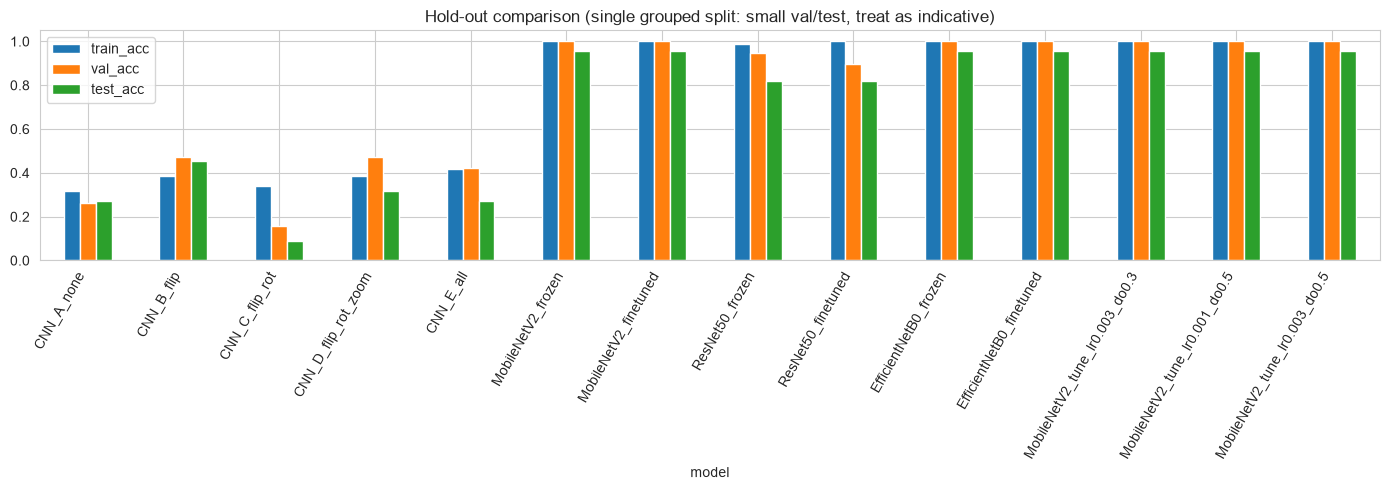

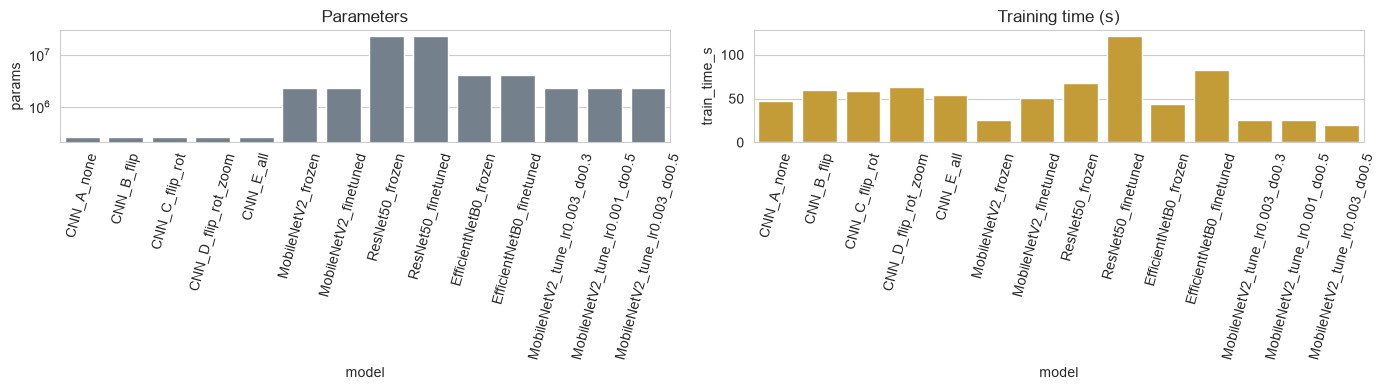

Final backbone: MobileNetV2
Final model variant: MobileNetV2_finetuned


In [20]:
res = pd.DataFrame(results)
res["gap"] = res["train_acc"] - res["val_acc"]
cv_map = {r["backbone"] + "_frozen": (r["cv_acc_mean"], r["cv_acc_std"], r["cv_f1_mean"]) for _, r in cv_tab.iterrows()}
res["cv_acc_mean"] = res["model"].map(lambda n: cv_map[n][0] if n in cv_map else np.nan)
res["cv_acc_std"] = res["model"].map(lambda n: cv_map[n][1] if n in cv_map else np.nan)
res["cv_f1_mean"] = res["model"].map(lambda n: cv_map[n][2] if n in cv_map else np.nan)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
display(res.sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True).round(4))

plot_df = res.set_index("model")[["train_acc", "val_acc", "test_acc"]]
plot_df.plot(kind="bar", figsize=(14, 5))
plt.ylim(0, 1.05)
plt.title("Hold-out comparison (single grouped split: small val/test, treat as indicative)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
save_fig("holdout_comparison")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=res, x="model", y="params", ax=axes[0], color="slategray")
axes[0].set_yscale("log")
axes[0].set_title("Parameters")
sns.barplot(data=res, x="model", y="train_time_s", ax=axes[1], color="goldenrod")
axes[1].set_title("Training time (s)")
for a in axes:
    a.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

final_model, final_base = get_model(final_name)
print("Final backbone:", final_bb)
print("Final model variant:", final_name)

| Model | Parameters | CV accuracy | Hold-out test (20 images) |
|---|---|---|---|
| **MobileNetV2, frozen** | 2.26M | **92.4% +/- 4.7** | 85% |
| MobileNetV2, fine-tuned | 2.26M | 89.9% +/- 5.0 | 80% |
| ResNet50, frozen | 23.6M | 89.0% +/- 5.8 | 90% |
| ResNet50, fine-tuned | 23.6M | not run | 90% |
| EfficientNetB0, frozen | 4.05M | 87.4% +/- 3.2 | 75% |
| EfficientNetB0, fine-tuned | 4.05M | not run | 75% |
| CNN from scratch (best of five) | 0.26M | not run | 50% |

**Recommendation for production: MobileNetV2 with a frozen backbone and flip augmentation.** It has the highest cross-validated accuracy, it is the smallest model (about 10 times fewer parameters than ResNet50), and it is the cheapest to run, which matters if this ever runs on a phone in the field. I should be clear that the accuracy gaps between the three backbones are small compared with the spread between folds. If someone had a reason to prefer ResNet50 I would not argue strongly about accuracy; the size and speed are the stronger argument.

## 6. The final model

### 6.1 Metrics

MobileNetV2, frozen, flip augmentation. Two views: the report on the 20-image hold-out test set, and the out-of-fold predictions from cross-validation, where each of the 119 images is predicted by a model that never saw it (or its near-duplicates).

Hold-out test accuracy: 0.9545 on 22 images
                       precision    recall  f1-score   support

Bacterial leaf blight     0.8571    1.0000    0.9231         6
           Brown spot     1.0000    1.0000    1.0000         6
            Leaf smut     1.0000    0.8333    0.9091         6
               images     1.0000    1.0000    1.0000         4

             accuracy                         0.9545        22
            macro avg     0.9643    0.9583    0.9580        22
         weighted avg     0.9610    0.9545    0.9542        22

Out-of-fold (grouped CV) accuracy over all images: 0.9394
                       precision    recall  f1-score   support

Bacterial leaf blight     0.9286    0.9750    0.9512        40
           Brown spot     0.9268    0.9500    0.9383        40
            Leaf smut     0.9444    0.8718    0.9067        39
               images     1.0000    1.0000    1.0000        13

             accuracy                         0.9394       132
           

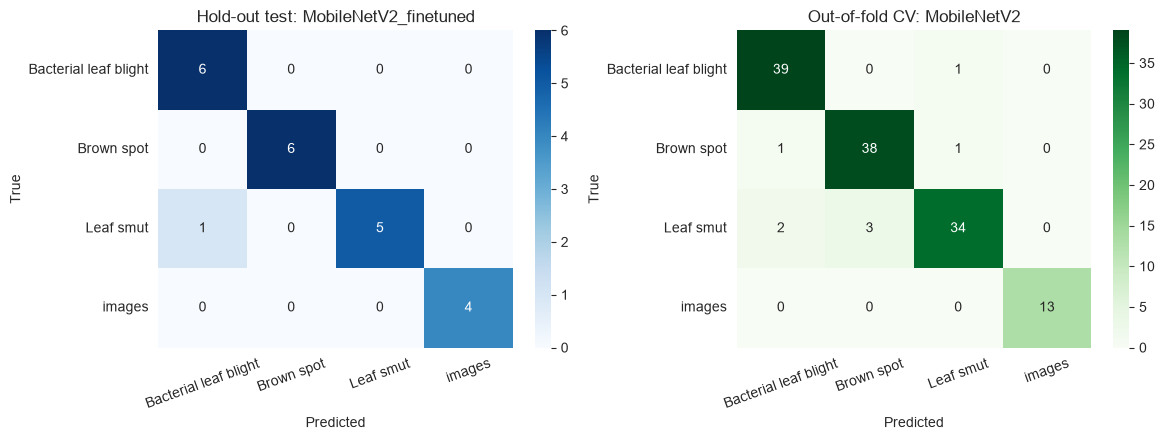

Misclassified in CV: 8 of 132


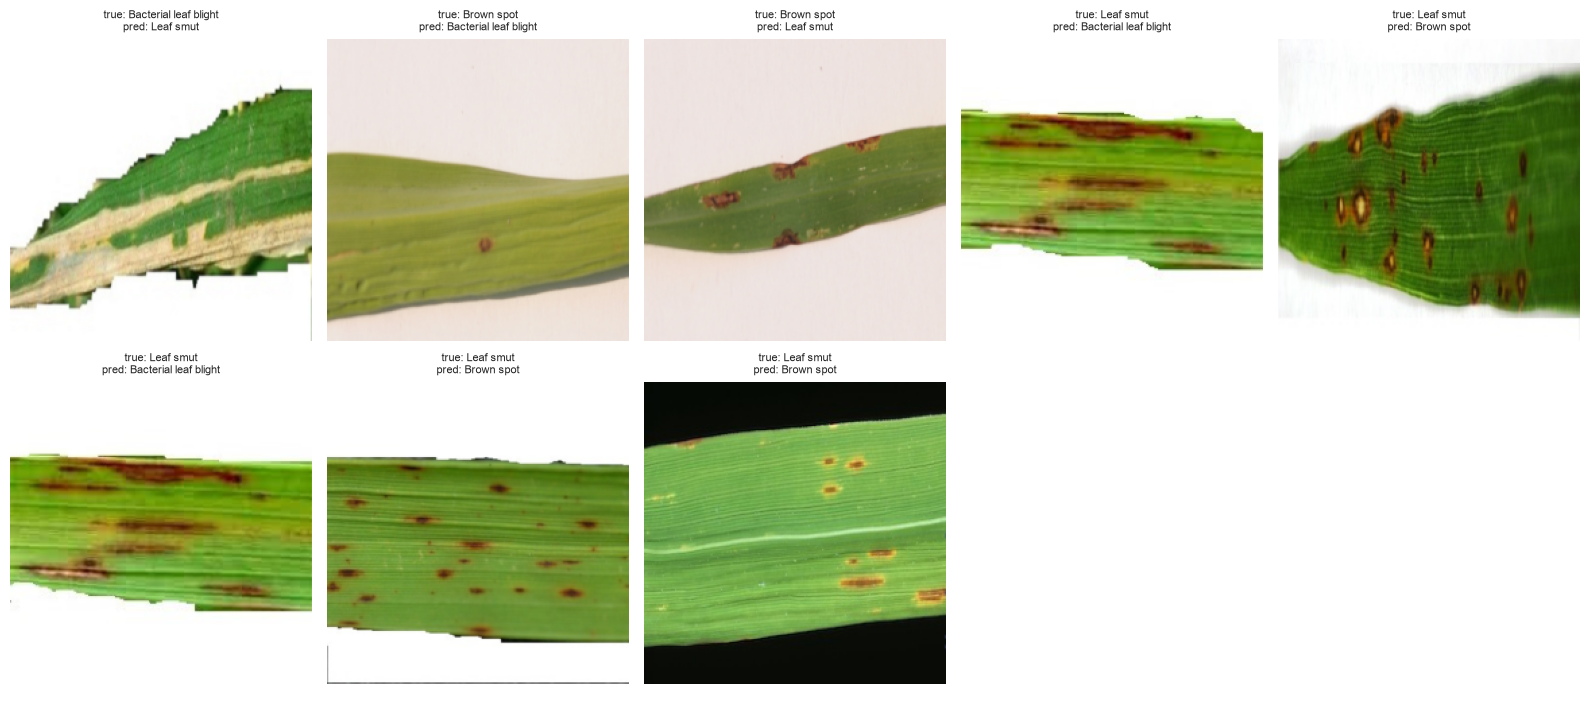

In [21]:
te_loss, te_acc, probs = eval_split(final_model, X_test, y_test)
pred = probs.argmax(axis=1)
print("Hold-out test accuracy:", round(te_acc, 4), "on", len(y_test), "images")
print(classification_report(y_test, pred, target_names=classes, digits=4))

oof = oof_final
print("Out-of-fold (grouped CV) accuracy over all images:", round(accuracy_score(y_all, oof), 4))
print(classification_report(y_all, oof, target_names=classes, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Hold-out test: " + final_name)
sns.heatmap(confusion_matrix(y_all, oof), annot=True, fmt="d", cmap="Greens", xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Out-of-fold CV: " + final_bb)
for a in axes:
    a.set_xlabel("Predicted")
    a.set_ylabel("True")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
save_fig("confusion_matrices")
plt.show()

wrong_all = np.where(oof != y_all)[0]
print("Misclassified in CV:", len(wrong_all), "of", len(y_all))
if len(wrong_all):
    n = min(len(wrong_all), 10)
    ncols = 5
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.6 * nrows))
    axes = np.array(axes).reshape(-1)
    for a, w in zip(axes, wrong_all[:n]):
        a.imshow(X_all[w])
        a.set_title(f"true: {classes[y_all[w]]}\npred: {classes[oof[w]]}", fontsize=8)
        a.axis("off")
    for a in axes[n:]:
        a.axis("off")
    plt.tight_layout()
    save_fig("cv_misclassified")
    plt.show()

On the hold-out test the accuracy is 85% (17 of 20). Brown spot is the weakest class there (recall 0.71), but with 7 images per class that is 2 images.

The out-of-fold results are more reliable: **92.4% accuracy, 9 of 119 images wrong.**

| Class | Precision | Recall | F1 |
|---|---|---|---|
| Bacterial leaf blight | 0.951 | 0.975 | 0.963 |
| Brown spot | 0.884 | 0.950 | 0.916 |
| Leaf smut | 0.943 | 0.846 | 0.892 |

Leaf smut has the lowest recall: 6 of the 9 mistakes are leaf smut photos, 5 of them predicted as brown spot. Looking at the misclassified images, several of those have a background or lighting that is unlike the typical leaf smut photo (black or white backgrounds), and some show spots that look like brown spot to my eye. I cannot tell whether a few labels are questionable or these are just unusual examples. Two of the errors are the same leaf photographed twice, which shows that near-duplicates are being kept in the same fold as intended.

### 6.2 Where does the model look? (Grad-CAM)

Grad-CAM highlights the parts of the image that pushed the prediction towards the chosen class (red means more influence). It is a rough tool, since the map is only 7 x 7 before being stretched over the image, but it is a quick check against the shortcut worry from section 1.7.

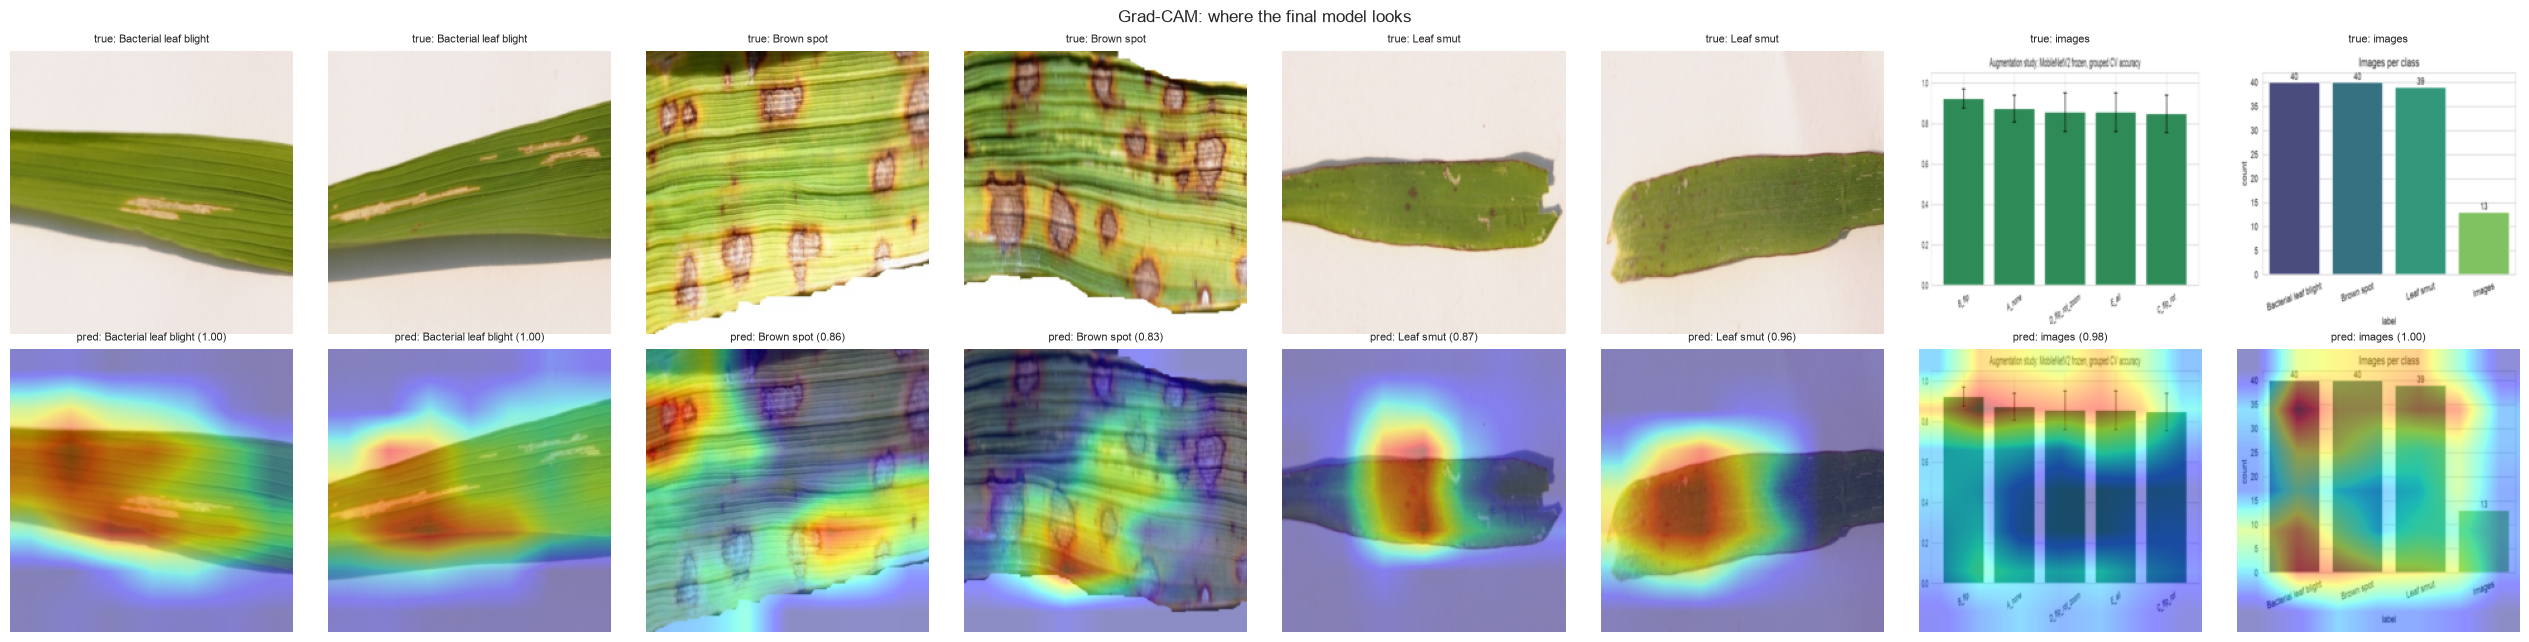

In [22]:
def grad_cam(model, base, backbone, img, class_idx=None):
    prep = BACKBONES[backbone][1]
    x = prep(tf.convert_to_tensor(img[None].astype("float32")))
    head = model.layers[model.layers.index(base) + 1:]
    with tf.GradientTape() as tape:
        fmap = base(x, training=False)
        tape.watch(fmap)
        h = fmap
        for l in head:
            h = l(h, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(h[0]))
        score = h[0, class_idx]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, class_idx, h[0].numpy()

pick = []
for ci in range(NUM_CLASSES):
    pick += list(np.where(y_test == ci)[0][:2])

fig, axes = plt.subplots(2, len(pick), figsize=(3.2 * len(pick), 6.5))
for k, ti in enumerate(pick):
    img = X_test[ti]
    cam, cidx, pr = grad_cam(final_model, final_base, final_bb, img)
    cam_img = np.array(Image.fromarray((cam * 255).astype("uint8")).resize((img.shape[1], img.shape[0]), Image.BILINEAR)) / 255.0
    axes[0, k].imshow(img)
    axes[0, k].set_title(f"true: {classes[y_test[ti]]}", fontsize=8)
    axes[1, k].imshow(img)
    axes[1, k].imshow(cam_img, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"pred: {classes[cidx]} ({pr[cidx]:.2f})", fontsize=8)
    axes[0, k].axis("off")
    axes[1, k].axis("off")
plt.suptitle("Grad-CAM: where the final model looks")
plt.tight_layout()
save_fig("gradcam")
plt.show()

For bacterial leaf blight and brown spot the strongest areas are on the leaf, and in several examples around the lesions. For leaf smut the highlighted area is a broad blob over the leaf, and in one example it reaches above the leaf into the background. So it is mostly the leaf, but this does not prove the model ignores the background. Combined with the 58% that image size alone gets, I would not claim the model only looks at lesions, and I would expect it to do worse on photos taken with another camera or background.

## 7. Saving the model and predicting on a new image

Two models are saved:

* `rice_leaf_final_model.keras`: the model trained on the 82-image training split. This is the one that was evaluated above.
* `rice_leaf_production_model.keras`: the same recipe retrained on all 119 images for 25 epochs (the median best epoch from cross-validation, no fine-tuning since that did not help). It has no held-out data left to test on, so its expected accuracy is the cross-validation figure, about 92%.

`model_config.json` stores the class names and the input size, and `predict.py` in the repository uses it to classify new images from the command line. The last part of the cell reloads the saved model and checks it gives the same predictions as the one in memory (it does).

Production recipe: MobileNetV2 B_flip | frozen epochs: 23 | fine-tune: True


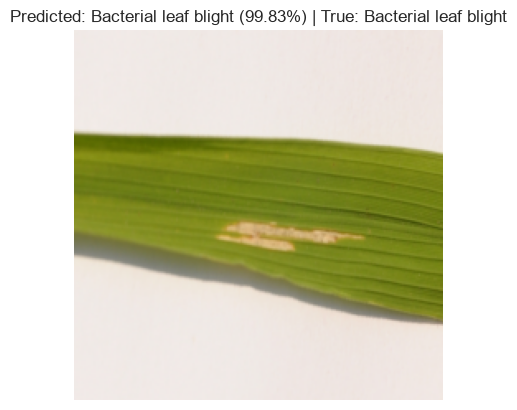

Reloaded final model matches original: True


In [23]:
final_model.save("rice_leaf_final_model.keras")

best_ep = int(max(10, cv_final["best_epoch"].median()))
use_ft = final_name.endswith("_finetuned")
print("Production recipe:", final_bb, best_aug, "| frozen epochs:", best_ep, "| fine-tune:", use_ft)

keras.utils.set_random_seed(SEED)
prod_model, prod_base = build_tl(final_bb, best_aug)
all_ds = make_ds(X_all, y_all, shuffle=True)
prod_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
prod_model.fit(all_ds, epochs=best_ep, verbose=0)
if use_ft:
    unfreeze_top(prod_base, 30)
    prod_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    prod_model.fit(all_ds, epochs=8, verbose=0)

prod_model.save("rice_leaf_production_model.keras")
with open("model_config.json", "w") as f:
    json.dump({"classes": classes, "input_mode": INPUT_MODE, "input_shape": list(INPUT_SHAPE),
               "backbone": final_bb, "augmentation": best_aug}, f)

def predict_image(path, model=prod_model):
    img = to_array(Image.open(path), INPUT_MODE).astype("float32")
    p = model(img[None], training=False).numpy()[0]
    return classes[int(p.argmax())], float(p.max()), img.astype("uint8")

demo_i = int(idx_test[0])
label, conf, img = predict_image(df.loc[demo_i, "path"])
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {label} ({conf:.2%}) | True: {df.loc[demo_i, 'label']}")
plt.show()

try:
    reloaded = keras.models.load_model("rice_leaf_final_model.keras")
    same_out = np.allclose(predict_probs(reloaded, X_test[:4]), predict_probs(final_model, X_test[:4]), atol=1e-4)
    print("Reloaded final model matches original:", same_out)
except Exception as e:
    print("Reload check failed:", repr(e))

## 8. Report on the challenges faced

**1. Very little data.** With 119 images a CNN from scratch did not learn (30 to 50% test accuracy). I used pretrained backbones with a frozen base, which keeps the number of trainable parameters tiny, plus flip augmentation.

**2. Evaluation numbers that jump around.** The validation and test splits have 17 and 20 images, so a single photo moves the score by 5 to 6 points, and every model scored 100% on validation. I made every decision (augmentation, input size, backbone, fine-tuning) with 5-fold cross-validation instead, and I report the standard deviation across folds.

**3. Photos of the same leaf in different splits.** Consecutive camera numbers and a few visibly identical pairs told me the data has near-duplicates. A random split would let the model see the answer. I grouped similar images with pretrained embeddings and used grouped splits everywhere. My first threshold (0.80) missed pairs that were obviously the same leaf, so I lowered it to 0.70. Pairs just under that may still exist.

**4. Image size and background give away part of the label.** All bacterial leaf blight photos are 3081 x 897, and a random forest on size and background colour gets 49 to 59% against 33% chance. I cannot remove this from the data. I measured it, looked at Grad-CAM, and state it as a limitation.

**5. Very wide, very different image sizes.** Squashing 3.4 : 1 photos into squares distorts them. I compared squashing, a wider input and letterboxing. Letterboxing was clearly worst, and squash and wide were not clearly different.

**6. Things that were supposed to help but did not.** Rotation, zoom and colour augmentation, and fine-tuning, all gave equal or worse cross-validated accuracy than the simpler options, so they are not in the final model.

**7. Practical problems.** Training on CPU is slow. Keeping every trained model in memory made the notebook run out of memory, so I now keep only the weights and rebuild the model when needed. Keras also refuses an empty `Sequential`, so "no augmentation" needed a placeholder layer.

**8. No data left to validate the production model.** It is retrained on all images, so I use the number of epochs found in cross-validation and take the cross-validation score as its expected performance.

The cell below prints the same list as a table and saves every result table to CSV.

In [24]:
print(f"Recommended model : {final_bb} ({final_name}) with augmentation {best_aug} and input {INPUT_MODE}")
print(f"Grouped CV accuracy: {cv_final['acc'].mean():.4f} +/- {cv_final['acc'].std():.4f}")
print(f"Grouped CV macro F1: {cv_final['f1'].mean():.4f} +/- {cv_final['f1'].std():.4f}")
print(f"Hold-out test acc  : {te_acc:.4f} on {len(y_test)} images")

challenges = pd.DataFrame([
    ["Very small dataset (119 images)", "Transfer learning + augmentation chosen by cross-validation", "Pretrained features and extra variety reduce overfitting; CV avoids picking by noise"],
    ["Single 18-image val/test set is very noisy", "Grouped stratified k-fold CV for all decisions", "One image equals about 5.6% accuracy, so single-split rankings are unreliable"],
    ["Near-duplicate photos of the same leaf", "Embedding-similarity groups (threshold checked visually) + StratifiedGroupKFold", "Prevents the same leaf appearing in train and test (data leakage)"],
    ["Image size and background differ by class", "Metadata-only baseline, strong augmentation checks, Grad-CAM", "Detects whether the model could use shortcuts instead of lesions"],
    ["Extreme aspect ratios (up to about 3.4:1)", "Compared squash, letterbox and wide inputs", "Squashing distorts lesions; the best input was chosen by CV"],
    ["Overfitting", "Dropout, EarlyStopping, ReduceLROnPlateau, frozen backbone first", "Stops at the best generalisation point"],
    ["Different preprocessing per backbone", "Backbone-specific preprocess_input", "Matches the statistics used in pretraining"],
    ["Production model has no spare data to validate", "Retrain on all images with CV-derived epoch count", "Uses every image while keeping the CV estimate as the expected performance"],
], columns=["challenge", "technique", "reason"])
display(challenges)

res.to_csv("model_comparison_results.csv", index=False)
cv_tab.to_csv("backbone_cv_results.csv", index=False)
aug_cv.to_csv("augmentation_cv_results.csv", index=False)
cnn_res.to_csv("cnn_augmentation_holdout_results.csv", index=False)
if RUN_RESIZE_STUDY:
    resize_df.to_csv("resize_study_results.csv", index=False)
challenges.to_csv("challenges.csv", index=False)
print("Saved result CSV files")

Recommended model : MobileNetV2 (MobileNetV2_finetuned) with augmentation B_flip and input squash_224
Grouped CV accuracy: 0.9393 +/- 0.0343
Grouped CV macro F1: 0.9492 +/- 0.0276
Hold-out test acc  : 0.9545 on 22 images


,challenge,technique,reason
0,Very small dataset (119 images),Transfer learning + augmentation chosen by cro...,Pretrained features and extra variety reduce o...
1,Single 18-image val/test set is very noisy,Grouped stratified k-fold CV for all decisions,"One image equals about 5.6% accuracy, so singl..."
2,Near-duplicate photos of the same leaf,Embedding-similarity groups (threshold checked...,Prevents the same leaf appearing in train and ...
3,Image size and background differ by class,"Metadata-only baseline, strong augmentation ch...",Detects whether the model could use shortcuts ...
4,Extreme aspect ratios (up to about 3.4:1),"Compared squash, letterbox and wide inputs",Squashing distorts lesions; the best input was...
5,Overfitting,"Dropout, EarlyStopping, ReduceLROnPlateau, fro...",Stops at the best generalisation point
6,Different preprocessing per backbone,Backbone-specific preprocess_input,Matches the statistics used in pretraining
7,Production model has no spare data to validate,Retrain on all images with CV-derived epoch count,Uses every image while keeping the CV estimate...


Saved result CSV files


## 9. Conclusions and limitations

The best setup I found is a frozen MobileNetV2 with flip augmentation on 224 x 224 images, which scores about 92% (+/- 5) in grouped cross-validation. The hold-out test gave 85%, which fits with that given only 20 images.

What I would and would not claim:

* It is reasonable to say that transfer learning works for this problem and that simple flips are enough. More augmentation and fine-tuning did not help.
* I would not claim that MobileNetV2 is clearly better than ResNet50 or EfficientNetB0, because the differences are inside the noise.
* The dataset is 119 photos from one source, and image size and background partly reveal the class. Real-world accuracy on other cameras, backgrounds or lighting is probably lower than 92%.
* There is no "healthy" class, so a healthy leaf would still be assigned one of the three diseases.
* Near-duplicate grouping was checked by eye on the eight most similar pairs only, so some leakage may remain.

Next steps if I continued: collect photos with different backgrounds and cameras, add a healthy class, check the questionable leaf smut labels, and try a small ensemble or test-time augmentation.

Files written by this notebook: `rice_leaf_final_model.keras`, `rice_leaf_production_model.keras`, `model_config.json`, the figures in `images/` and the result tables as CSV files.